<a href="https://colab.research.google.com/github/elbabs/Explainable-Student-Stress-Screening-with-Machine-Learning/blob/main/tudent_Stress_Analysis_Noteboook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Student Stress Level Prediction

## Introduction
Student stress is a common problem in educational institutions. Students can experience stress from several areas of their lives, including academic workload, poor sleep, financial or living conditions, social pressure, concerns about their future, and other personal challenges.
One challenge is that students experiencing high levels of stress may not always be identified early. In a school or university with many students, it can be difficult for counsellors, lecturers, or student support teams to assess every student's situation regularly.
This project proposes the use of machine learning to analyse student-related factors and predict their stress level. The idea is not to diagnose a student, but to investigate whether available data can be used to identify patterns associated with different levels of stress.
If successful, such a system could serve as a prototype for helping educational institutions identify students or groups that may require further attention and support.

## Objective
The main objective of this project is to develop a machine learning model that can predict a student's stress level based on factors related to their psychological, physiological, academic, environmental, and social conditions.
The project will also examine the data to understand which factors are most associated with the different stress levels.

## Dataset Variables and Description

This dataset contains 3000 anonymized responses collected from undergraduate students
(aged 19–24) studying at public, private, and national universities in Bangladesh.
It includes academic, lifestyle, socio-economic, and psychological attributes along with
derived stress metrics.

These features represent factors that may be associated with students' stress levels. The target variable, `Stress_Level`, represents the stress category the model aims to predict.

| SN | Variable Name | Type | Data Description |
|---|---|---|---|
|1|	Age | Numeric | Student's age (19–24)|
|2|	Gender | Categorical | Male, Female, Other |
|3|	University_Type| Categorical |Public, Private, National University|
|4|	Study_Hours| Numeric | Daily study hours|
|5|	Class_Attendance| Numeric | Percentage of attendance per semester|
|6|	Tuition| Categorical | Yes / No (extra coaching)|
|7|	Exam_Frequency|	Numeric | Exam frequency rated 1–10|
|8|	Assignment_Load| Numeric | Assignment load rated 1–10|
|9|	Sleep_Hours| Numeric | Daily sleep duration|
|10| Social_Media_Use| Numeric | Hours per day on social media|
|11| Screen_Time| Numeric | Total screen hours per day|
|12| Physical_Exercise|	Categorical | Yes / No |
|13| Family_Income_Level| Categorical | Low, Medium, High|
|14| Peer_Pressure|	Numeric	| Self-rated peer pressure (1–10)|
|15| Family_Support| Numeric | Self-rated family support level (1–10)|
|16| Anxiety_Level|	Numeric	| Self-rated anxiety level (1–10)|
|17| Stress_Score| Numeric | Derived combined stress score|
|18| Stress_Level| Categorical | Low, Medium, High|


# 1. Importing Libraries and Dataframe

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
import gdown

# Download university_student_stress_dataset.csv from Google Drive
file_id = '1NqrZRpY9u_MwHjFh3Qx6Og7CLZmjC_nv'
output_filename = 'university_student_stress_dataset.csv'

gdown.download(id=file_id, output=output_filename, quiet=False)

# Load into a pandas DataFrame
df = pd.read_csv(output_filename)


# Importing the dataset
#df = pd.read_csv('university_student_stress_dataset.csv')

Downloading...
From: https://drive.google.com/uc?id=1NqrZRpY9u_MwHjFh3Qx6Og7CLZmjC_nv
To: /content/university_student_stress_dataset.csv
100%|██████████| 213k/213k [00:00<00:00, 82.3MB/s]


# 2. Data Understanding and Preprocessing

In [ ]:
df.head()

,Age,Gender,Study_Hours,Class_Attendance,Tuition,Exam_Frequency,Assignment_Load,Sleep_Hours,Physical_Exercise,Social_Media_Use,Screen_Time,Family_Income_Level,Peer_Pressure,Family_Support,Anxiety_Level,University_Type,Stress_Score,Stress_Level
0,24,Male,9,71,No,7,4,6,Yes,6,9,Low,6,3,5,National University,20,Medium
1,24,Female,8,43,Yes,6,8,5,Yes,6,8,Medium,3,7,8,National University,22,High
2,21,Female,4,56,Yes,3,6,5,Yes,7,9,Low,2,5,3,Private University,16,Medium
3,23,Female,4,46,No,8,6,8,No,5,6,Medium,8,6,5,Private University,16,Medium
4,20,Male,8,46,No,5,1,6,Yes,0,7,Medium,5,6,2,National University,1,Low


In [ ]:
df.shape

(3000, 18)

We have 3,000 (Student's entries) Rows and 18 Features

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 18 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   Age                  3000 non-null   int64 
 1   Gender               3000 non-null   object
 2   Study_Hours          3000 non-null   int64 
 3   Class_Attendance     3000 non-null   int64 
 4   Tuition              3000 non-null   object
 5   Exam_Frequency       3000 non-null   int64 
 6   Assignment_Load      3000 non-null   int64 
 7   Sleep_Hours          3000 non-null   int64 
 8   Physical_Exercise    3000 non-null   object
 9   Social_Media_Use     3000 non-null   int64 
 10  Screen_Time          3000 non-null   int64 
 11  Family_Income_Level  3000 non-null   object
 12  Peer_Pressure        3000 non-null   int64 
 13  Family_Support       3000 non-null   int64 
 14  Anxiety_Level        3000 non-null   int64 
 15  University_Type      3000 non-null   object
 16  Stress

All 18 columns have 3,000 non-null values, so nothing is missing. Twelve columns are numeric (`int64`) and six are text (`object`): `Gender`, `Tuition`, `Physical_Exercise`, `Family_Income_Level`, `University_Type` and `Stress_Level`. The text columns will need to be encoded as numbers before they can go into a model.

In [ ]:
print("Descriptive Statistics:")
display(df.describe(include='all').T)

Descriptive Statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Age,3000.0,NaN,NaN,NaN,21.517333,1.705678,19.0,20.0,21.0,23.0,24.0
Gender,3000,2,Female,1538,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Study_Hours,3000.0,NaN,NaN,NaN,4.488667,2.858659,0.0,2.0,4.0,7.0,9.0
Class_Attendance,3000.0,NaN,NaN,NaN,68.872333,17.442576,40.0,54.0,69.0,84.0,99.0
Tuition,3000,2,No,1545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Exam_Frequency,3000.0,NaN,NaN,NaN,5.025667,2.592023,1.0,3.0,5.0,7.0,9.0
Assignment_Load,3000.0,NaN,NaN,NaN,4.996,2.594654,1.0,3.0,5.0,7.0,9.0
Sleep_Hours,3000.0,NaN,NaN,NaN,6.519,1.687381,4.0,5.0,7.0,8.0,9.0
Physical_Exercise,3000,2,No,1551,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Social_Media_Use,3000.0,NaN,NaN,NaN,3.487,2.288721,0.0,2.0,3.0,5.0,7.0


The table summarises every column. For the numeric columns, the mean and median are almost identical (for example `Study_Hours` has mean 4.49 and median 4, and `Anxiety_Level` has mean 5.00 and median 5), which means the values are spread symmetrically. The minimum and maximum also stay inside the expected ranges (ages 19 to 24, attendance 40% to 99%, sleep 4 to 9 hours), so there are no impossible entries. `Stress_Score` is the only column that goes negative (minimum -9, maximum 33), because it is a calculated score rather than a survey answer. For the text columns, the groups are well balanced (for example 1,538 females out of 3,000).

In [ ]:
print("Unique Values Per Columns: ")
display(df.nunique())

Unique Values Per Columns: 


Age                     6
Gender                  2
Study_Hours            10
Class_Attendance       60
Tuition                 2
Exam_Frequency          9
Assignment_Load         9
Sleep_Hours             6
Physical_Exercise       2
Social_Media_Use        8
Screen_Time            11
Family_Income_Level     3
Peer_Pressure           9
Family_Support          9
Anxiety_Level           9
University_Type         3
Stress_Score           42
Stress_Level            3
dtype: int64

In [ ]:
for col in df.columns:
    print(f"Unique Values in {col}: {df[col].unique()}")

Unique Values in Age: [24 21 23 20 19 22]
Unique Values in Gender: ['Male' 'Female']
Unique Values in Study_Hours: [9 8 4 2 0 6 7 5 3 1]
Unique Values in Class_Attendance: [71 43 56 46 95 85 52 74 50 89 49 88 48 68 64 61 77 83 84 79 90 92 75 62
 97 40 78 59 47 45 70 87 60 96 98 73 57 94 91 67 82 69 93 86 54 44 80 66
 53 63 81 76 58 41 99 72 55 42 51 65]
Unique Values in Tuition: ['No' 'Yes']
Unique Values in Exam_Frequency: [7 6 3 8 5 9 1 4 2]
Unique Values in Assignment_Load: [4 8 6 1 2 5 3 9 7]
Unique Values in Sleep_Hours: [6 5 8 7 9 4]
Unique Values in Physical_Exercise: ['Yes' 'No']
Unique Values in Social_Media_Use: [6 7 5 0 3 2 4 1]
Unique Values in Screen_Time: [ 9  8  6  7  4  1  3 11  2  5 10]
Unique Values in Family_Income_Level: ['Low' 'Medium' 'High']
Unique Values in Peer_Pressure: [6 3 2 8 5 7 1 4 9]
Unique Values in Family_Support: [3 7 5 6 9 1 8 4 2]
Unique Values in Anxiety_Level: [5 8 3 2 1 9 4 7 6]
Unique Values in University_Type: ['National University' 'Private Un

This lists every distinct value found in each column, which is a quick way to catch typos, odd spellings or out-of-range entries. None show up.

In [ ]:
print("\nStress-level counts:")
print(df["Stress_Level"].value_counts())


Stress-level counts:
Stress_Level
Medium    1431
Low       1243
High       326
Name: count, dtype: int64


The target is imbalanced. Medium is the largest group (1,431 students, about 48%), followed by Low (1,243, about 41%), while High has only 326 students (about 11%). A model could score roughly 48% accuracy just by always predicting "Medium", and it could ignore the High group almost completely. Because High is the group we most want to catch, we should not judge the model on accuracy alone. We should use stratified splitting and look at per-class precision, recall and F1.

## 2.1 Checking for Duplicates

In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


There appears to be no dupplicates in the dataset. That's Great!

## 2.2 Checking for Null Values

In [ ]:
print("Missing Values:")
df.isnull().sum()

Missing Values:


Age                    0
Gender                 0
Study_Hours            0
Class_Attendance       0
Tuition                0
Exam_Frequency         0
Assignment_Load        0
Sleep_Hours            0
Physical_Exercise      0
Social_Media_Use       0
Screen_Time            0
Family_Income_Level    0
Peer_Pressure          0
Family_Support         0
Anxiety_Level          0
University_Type        0
Stress_Score           0
Stress_Level           0
dtype: int64

## 2.3 Summary Statistic and Outlier Detection

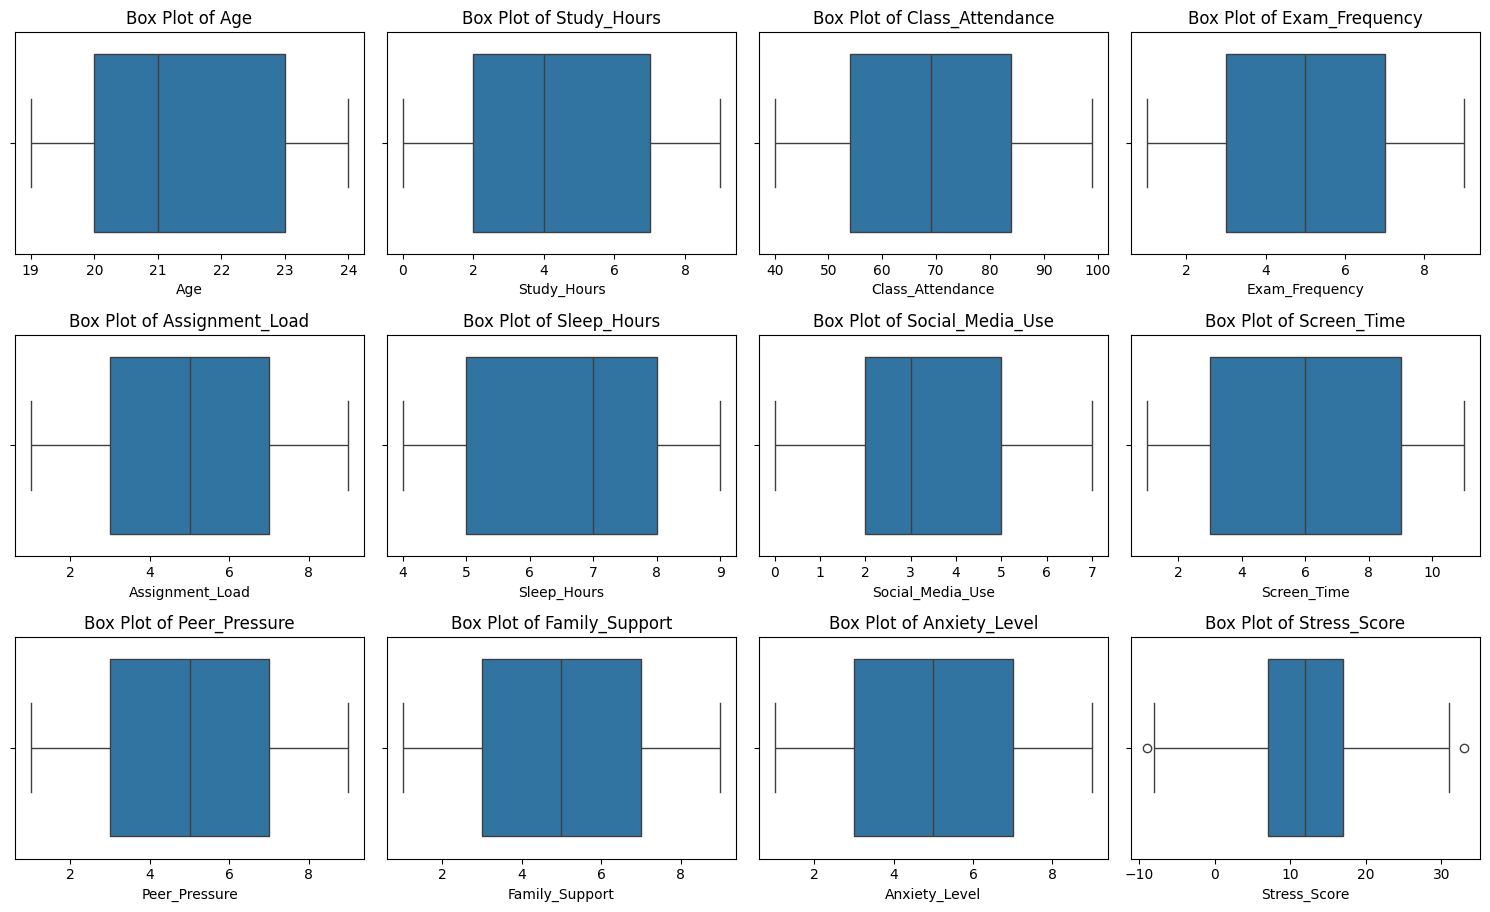

In [ ]:
# Filter numerical columns for box plots
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns

# Plot box plots for each numerical feature
plt.figure(figsize=(15, len(numerical_features) * 3))  # Adjust size based on the number of features

for i, col in enumerate(numerical_features, 1):
    plt.subplot(len(numerical_features), 4, i)
    sns.boxplot(x=df[col])
    plt.title(f"Box Plot of {col}")
    plt.tight_layout()

plt.show()

#the job of enumerate(numerical_features, 1)
#is to loop over the list 'numerical_features' while also keeping track of an index i starting from 1.

Each box shows the middle 50% of values (the box), the median (the line inside it) and the typical range (the whiskers). Dots beyond the whiskers would mark outliers. Here the whiskers reach the minimum and maximum of every feature and no dots appear. The boxes are also centred in the middle of their ranges, which fits the near-zero skewness we see later. Notice that the plots for 0-to-9 scales look alike, which suggests the values are spread fairly evenly across the scale rather than bunched around a typical value. `Stress_Score` is included in this grid, but it is an outcome rather than a predictor.

In [ ]:
import pandas as pd

# Select only numerical feature columns, explicitly excluding target variables
features = df.drop(columns=["Stress_Score" , 'Stress_Level']).select_dtypes(include="number").columns

outlier_summary = []

for col in features:
    # Calculate Interquartile Range (IQR) bounds using the standard 1.5 * IQR rule
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    # Create a boolean mask to flag values falling outside the normal distribution bounds
    mask = (df[col] < lower_bound) | (df[col] > upper_bound)

    outlier_summary.append({
                            "Feature": col,
                            "Lower Bound": lower_bound,
                            "Upper Bound": upper_bound,
                            "Potential Outliers": int(mask.sum())
                            })

outlier_df = pd.DataFrame(outlier_summary)
print(outlier_df.to_string(index=False))

         Feature  Lower Bound  Upper Bound  Potential Outliers
             Age         15.5         27.5                   0
     Study_Hours         -5.5         14.5                   0
Class_Attendance          9.0        129.0                   0
  Exam_Frequency         -3.0         13.0                   0
 Assignment_Load         -3.0         13.0                   0
     Sleep_Hours          0.5         12.5                   0
Social_Media_Use         -2.5          9.5                   0
     Screen_Time         -6.0         18.0                   0
   Peer_Pressure         -3.0         13.0                   0
  Family_Support         -3.0         13.0                   0
   Anxiety_Level         -3.0         13.0                   0


This table applies the standard IQR rule. A value is flagged if it falls below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR. All the predictors report **0 potential outliers**. The bounds are also wider than the real scales (for example attendance bounds of 9 to 129 against real values of 40 to 99), so nothing can fall outside them. We therefore keep every row and apply no outlier treatment. `Stress_Score` and `Stress_Level` were left out on purpose because they are outcomes.

# 3. Exploitary Data Analysis (EDA)

In [ ]:
#seperating data into numeric and categorical
cat_df = df.select_dtypes(include = ['object'])

numerical_df = df.select_dtypes(include = ['int64' , 'float64'])

## 3.1 Univariate non-graphical (UNG)

In [ ]:
def cat_univariate_analysis(discrete_data):
    # Performs univariate analysis on categorical features by printing summary metrics (count, unique values) and value counts.
    for col_name in discrete_data:
        print("*" * 10, col_name, "*" * 10)
        print(discrete_data[col_name].agg(['count', 'unique', 'nunique']))
        print()
        print('Value Counts:\n', discrete_data[col_name].value_counts())
        print()

cat_univariate_analysis(cat_df)

********** Gender **********
count                3000
unique     [Male, Female]
nunique                 2
Name: Gender, dtype: object

Value Counts:
 Gender
Female    1538
Male      1462
Name: count, dtype: int64

********** Tuition **********
count           3000
unique     [No, Yes]
nunique            2
Name: Tuition, dtype: object

Value Counts:
 Tuition
No     1545
Yes    1455
Name: count, dtype: int64

********** Physical_Exercise **********
count           3000
unique     [Yes, No]
nunique            2
Name: Physical_Exercise, dtype: object

Value Counts:
 Physical_Exercise
No     1551
Yes    1449
Name: count, dtype: int64

********** Family_Income_Level **********
count                     3000
unique     [Low, Medium, High]
nunique                      3
Name: Family_Income_Level, dtype: object

Value Counts:
 Family_Income_Level
Medium    1333
Low       1059
High       608
Name: count, dtype: int64

********** University_Type **********
count                                  

For each text column, this prints how many records there are, which categories exist and how often each appears. Gender (1,538 Female, 1,462 Male), Tuition (1,545 No, 1,455 Yes), Physical_Exercise (1,551 No, 1,449 Yes) and University_Type (about 1,000 per type) are almost perfectly balanced. `Family_Income_Level` is the exception, with Medium the most common (1,333) and High the least common. The target column shows the imbalance already noted (Medium 1,431, Low 1,243, High 326).

In [ ]:
def numerical_univariate_analysis(numerical_data):
    """Performs univariate analysis on numerical features by
       printing summary statistics including central tendency, dispersion, and distribution shape."""
    for col_name in numerical_data:
        print("*" * 10, col_name, "*" * 10)
        print(numerical_data[col_name].agg(['min', 'max', 'mean', 'median', 'std', 'kurt', 'skew']))
        print()

numerical_univariate_analysis(numerical_df)

********** Age **********
min       19.000000
max       24.000000
mean      21.517333
median    21.000000
std        1.705678
kurt      -1.264382
skew      -0.005428
Name: Age, dtype: float64

********** Study_Hours **********
min       0.000000
max       9.000000
mean      4.488667
median    4.000000
std       2.858659
kurt     -1.195318
skew      0.013280
Name: Study_Hours, dtype: float64

********** Class_Attendance **********
min       40.000000
max       99.000000
mean      68.872333
median    69.000000
std       17.442576
kurt      -1.204096
skew       0.034575
Name: Class_Attendance, dtype: float64

********** Exam_Frequency **********
min       1.000000
max       9.000000
mean      5.025667
median    5.000000
std       2.592023
kurt     -1.220359
skew     -0.011928
Name: Exam_Frequency, dtype: float64

********** Assignment_Load **********
min       1.000000
max       9.000000
mean      4.996000
median    5.000000
std       2.594654
kurt     -1.241160
skew     -0.013137
Name: A

For every numeric column the function prints the range, mean, median, spread (`std`), skewness (`skew`) and kurtosis (`kurt`). Two things stand out:

- **Skewness is almost exactly 0** for every column (between about -0.04 and 0.03), so no column leans left or right. Means and medians match.
- **Kurtosis is about -1.2** for every predictor. A value near -1.2 is what a flat, evenly spread (uniform) distribution produces, which means the values are spread almost equally across the scale, with no peak in the middle and no heavy tails.

`Stress_Score` is the only column that looks different (kurtosis -0.26), meaning it is closer to a bell shape. This is expected because it is built by combining several columns. No transformation (log, square-root, etc.) is needed for the predictors.

## 3.2 Univariate Graphical

### 3.2.1 Numerical Analaysis

In [ ]:
# Determine grid row count assuming a 3-column layout for upcoming visualizations
num_cols = len(numerical_df.columns)
print(numerical_df.columns)
print(num_cols)
print(num_cols // 3)

Index(['Age', 'Study_Hours', 'Class_Attendance', 'Exam_Frequency',
       'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use', 'Screen_Time',
       'Peer_Pressure', 'Family_Support', 'Anxiety_Level', 'Stress_Score'],
      dtype='object')
12
4


**What this cell does:** it is a small helper calculation. It confirms that there are 12 numeric columns and that `12 // 3 = 4`. This was used to decide the layout of the histogram grid (3 rows by 4 columns) in the next cell.

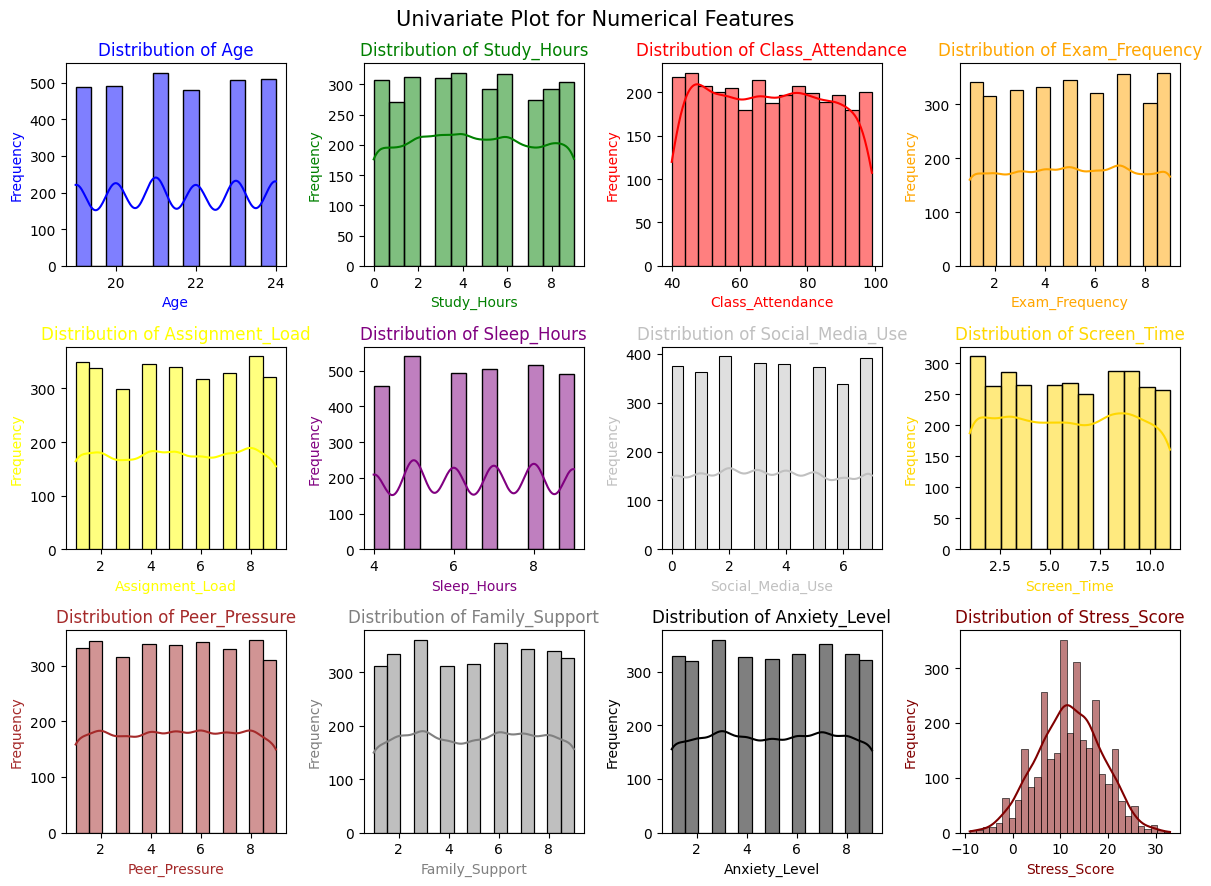

In [ ]:
def univariate_analysis(numerical_data):
    # Plots the distribution (histogram with KDE) of each numerical feature in a grid layout, handling any unused subplots.
    num_cols = len(numerical_data)
    fig, axs = plt.subplots(nrows=3, ncols=4, figsize=(12, 9))
    plt.suptitle("Univariate Plot for Numerical Features", fontsize=15)

    # Flatten the 2D axes array for easy sequential iteration
    axs = axs.flatten()

    colours = ['blue', 'green', 'red', 'orange', 'yellow', 'purple',
               'silver', 'gold', 'brown', 'grey', 'black', 'maroon']

    for i, col_name in enumerate(numerical_data.columns):
        sns.histplot(data=numerical_data, x=col_name, kde=True, ax=axs[i], color=colours[i], edgecolor='k')
        axs[i].set_title(f'Distribution of {col_name}', color=colours[i])
        axs[i].set_xlabel(col_name, color=colours[i])
        axs[i].set_ylabel('Frequency', color=colours[i])

    # Adjust layout spacing once after plotting all features
    plt.tight_layout()

    # Hide any leftover/empty subplots in the grid
    for j in range(len(numerical_data.columns), len(axs)):
        fig.delaxes(axs[j])

    plt.show()

univariate_analysis(numerical_df)

The shapes are consistent with the statistics above. Almost every predictor has bars of roughly equal height across its whole range, which gives a flat, block-like outline, and the KDE line stays close to a straight line. There is no tall peak and no long tail. The bars look separate because these are whole number scales. The one different shape is `Stress_Score`, which rises to a hump in the middle and falls away on both sides, in line with its lower kurtosis.

### 3.2.2 Categorical Analysis

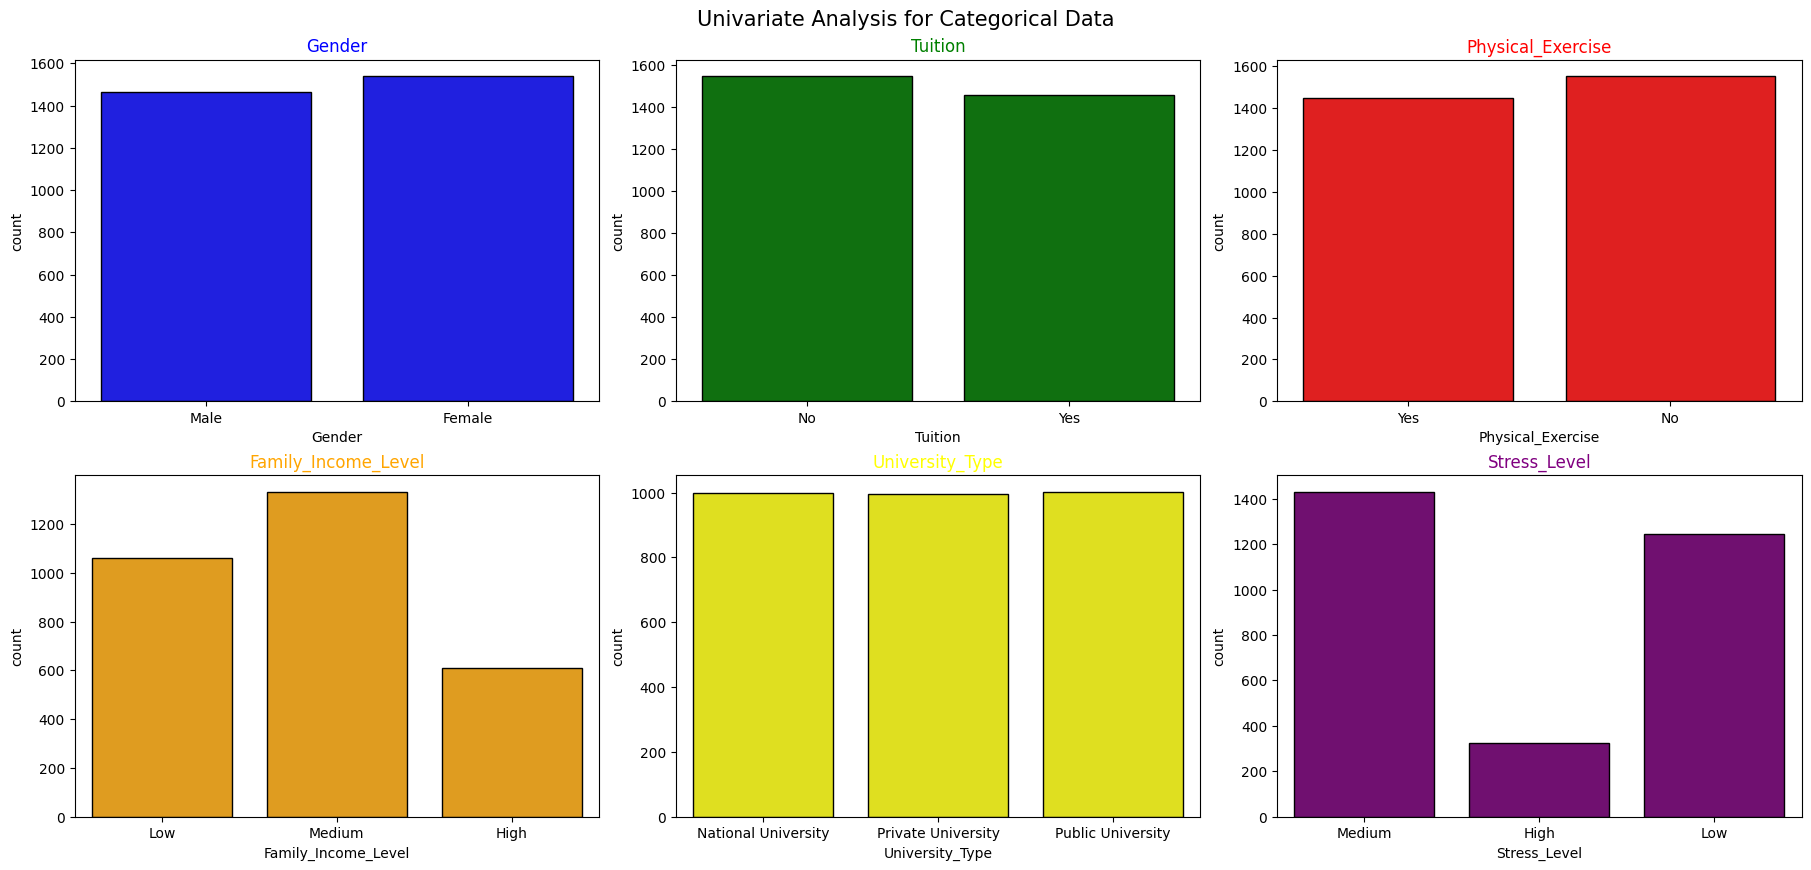

In [ ]:
def categorical_univariate(cat_data):
    # Plots the count distribution of each categorical feature in a grid layout, handling any unused subplots.
    fig, axs = plt.subplots(3, 3, figsize=(18, 12), constrained_layout=True)
    plt.suptitle("Univariate Analysis for Categorical Data", fontsize=15)

    axs = axs.flatten()

    colours = ['blue', 'green', 'red', 'orange', 'yellow',
               'purple', 'grey', 'gold', 'brown', 'cyan', 'black']

    for i, column_name in enumerate(cat_data.columns):
        axs[i].set_title(column_name, color=colours[i])
        sns.countplot(data=cat_data, x=column_name, color=colours[i], edgecolor='k', ax=axs[i])

    # Hide any leftover/empty subplots in the grid
    for j in range(len(cat_data.columns), len(axs)):
        fig.delaxes(axs[j])

    plt.show()

categorical_univariate(cat_df)

`Gender`, `Tuition`, `Physical_Exercise` and `University_Type` have bars of nearly equal height, so the groups are well balanced. `Family_Income_Level` is uneven. Medium income is the largest group (about 1,330), then Low (about 1,060), then High (about 610), so conclusions about high-income students rest on fewer records. The final panel shows the imbalanced target, with High stress clearly the smallest class.

## 3.3 Relationship Analysis

### 3.3.1 Violin plots to check numerical features vs. stress level
Violin plots show how the values of a numerical feature are distributed within each stress category. The inner box shows the median and interquartile range.

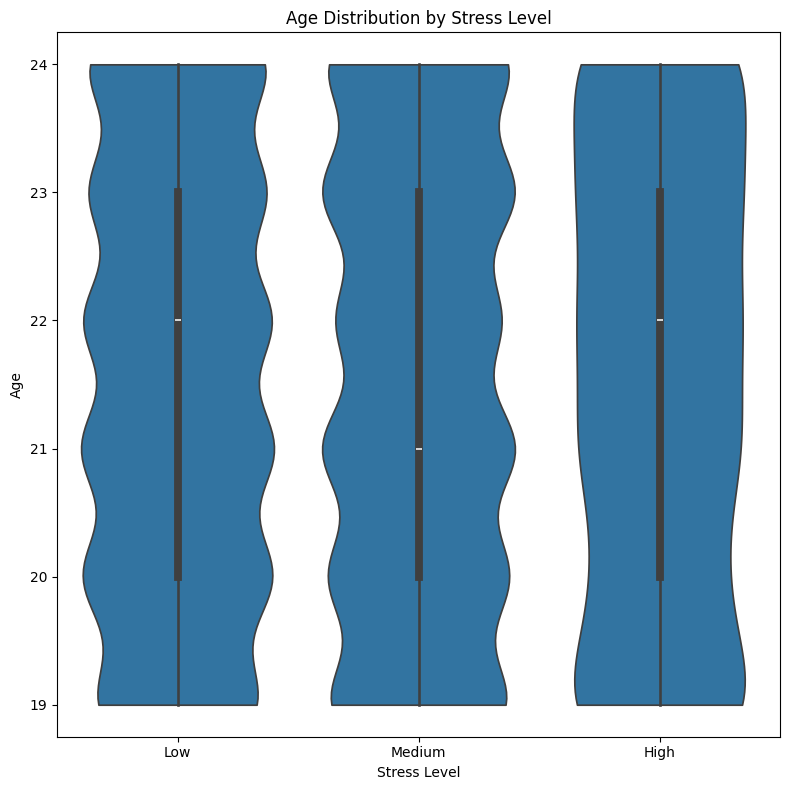

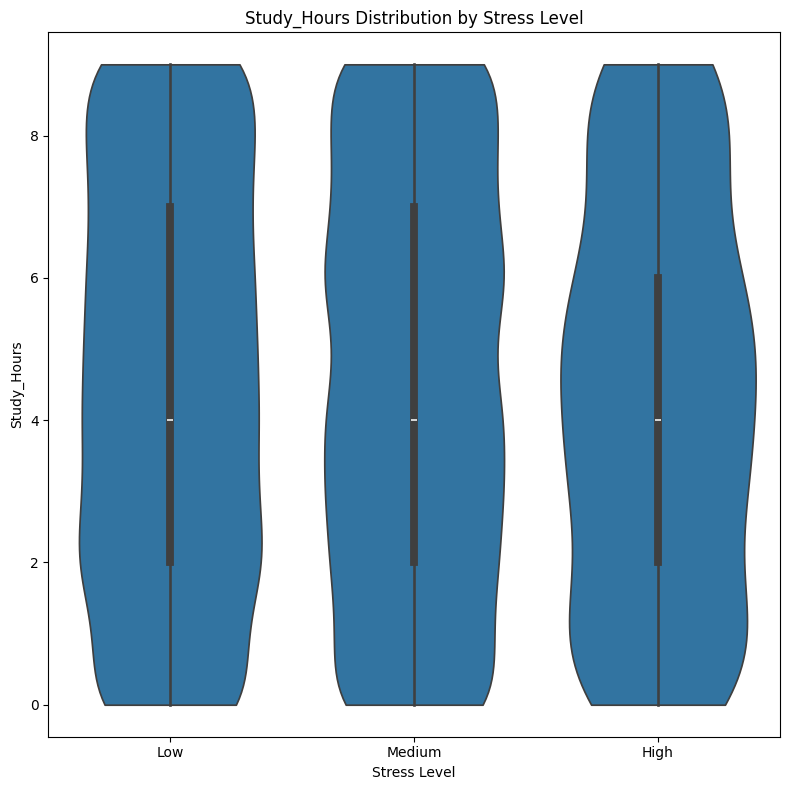

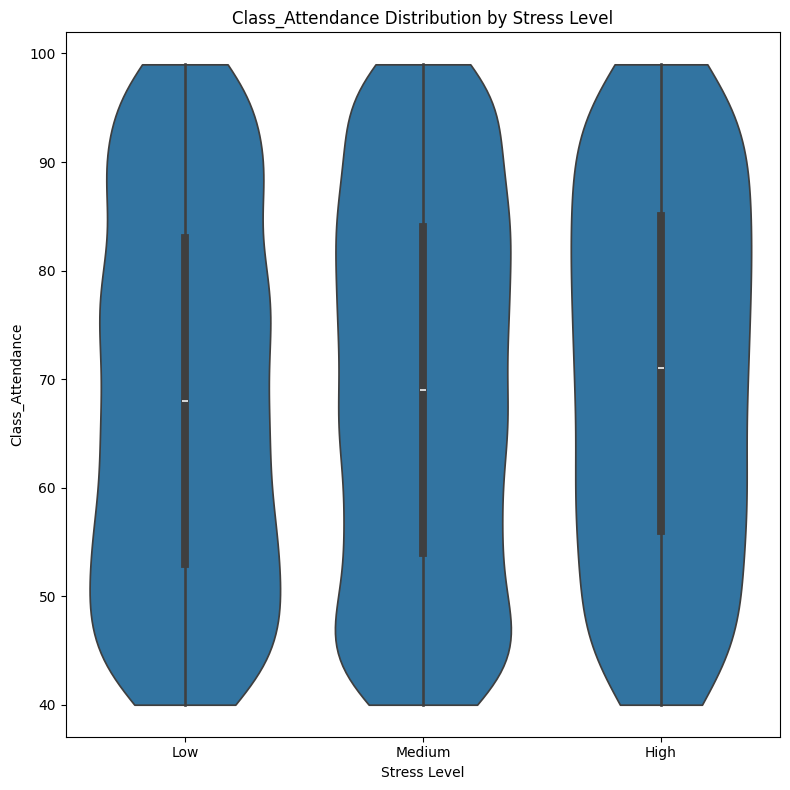

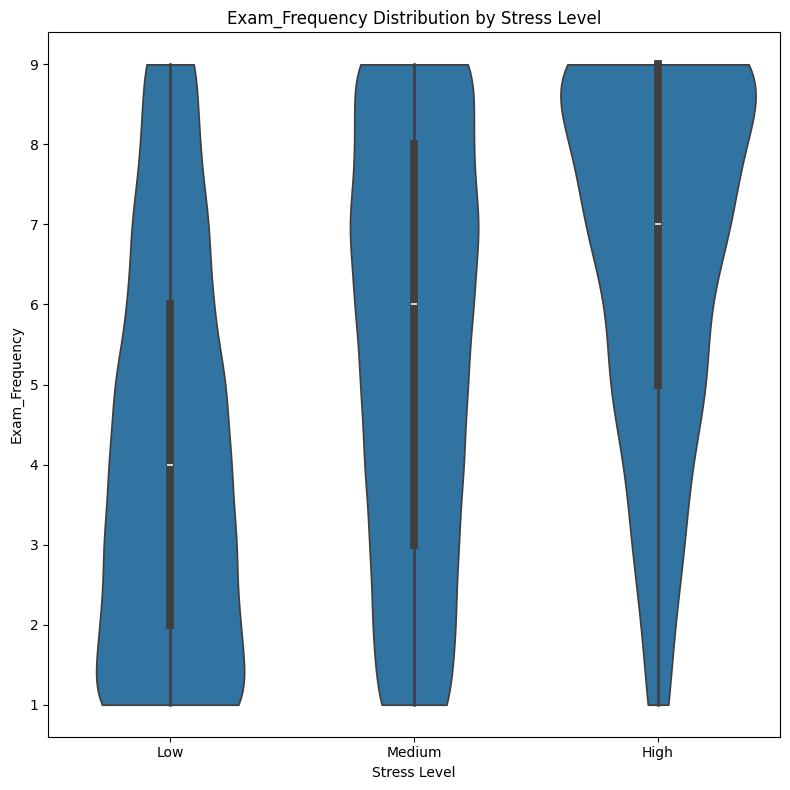

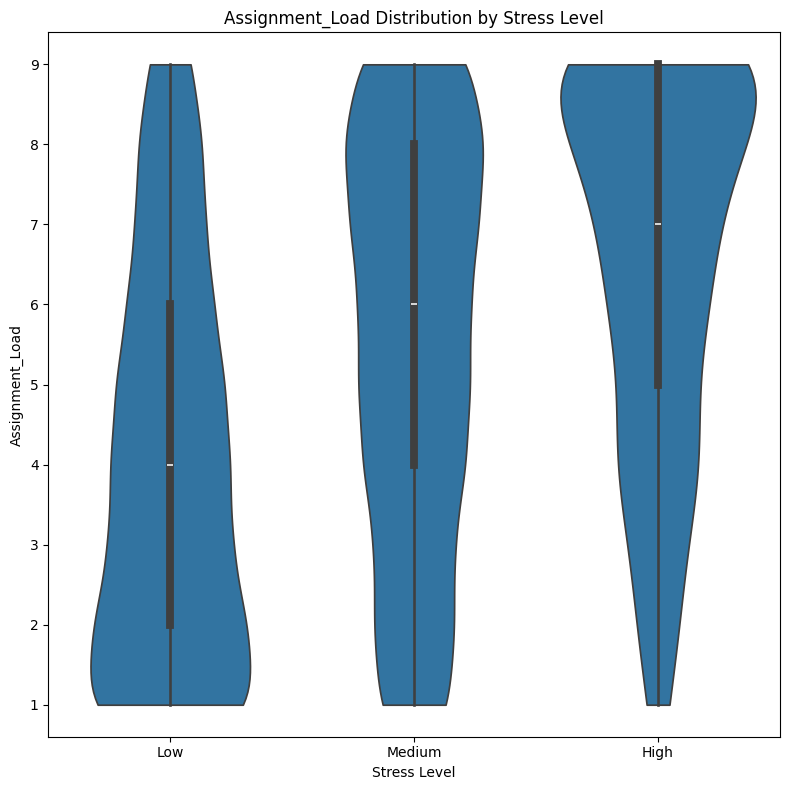

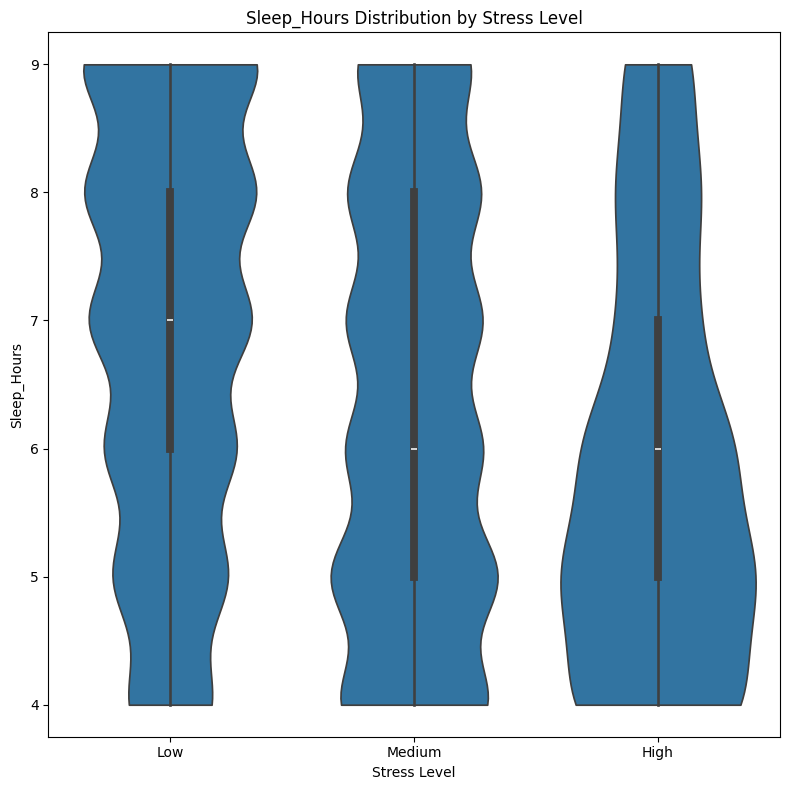

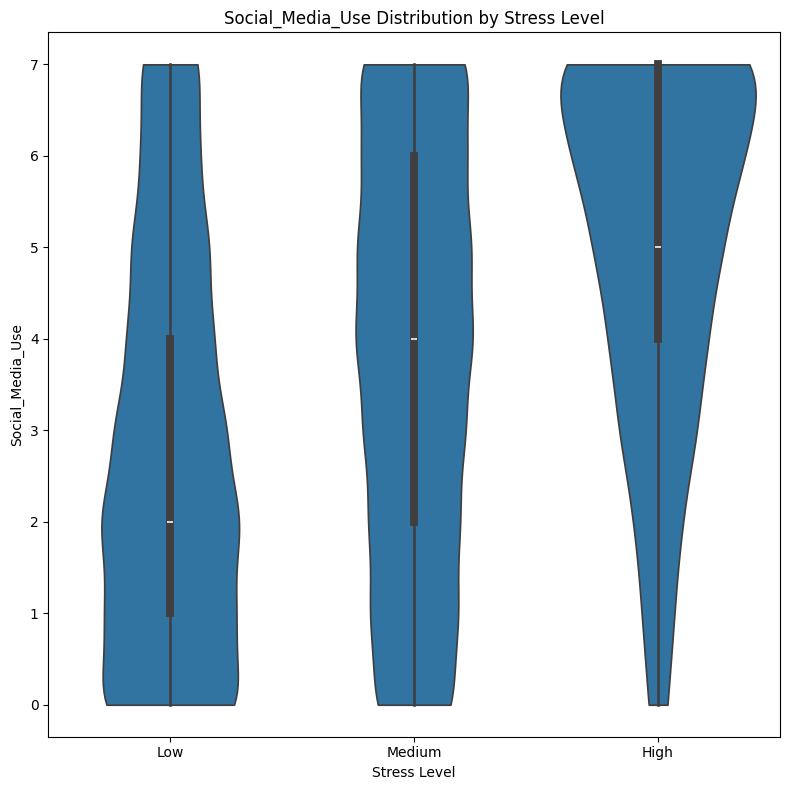

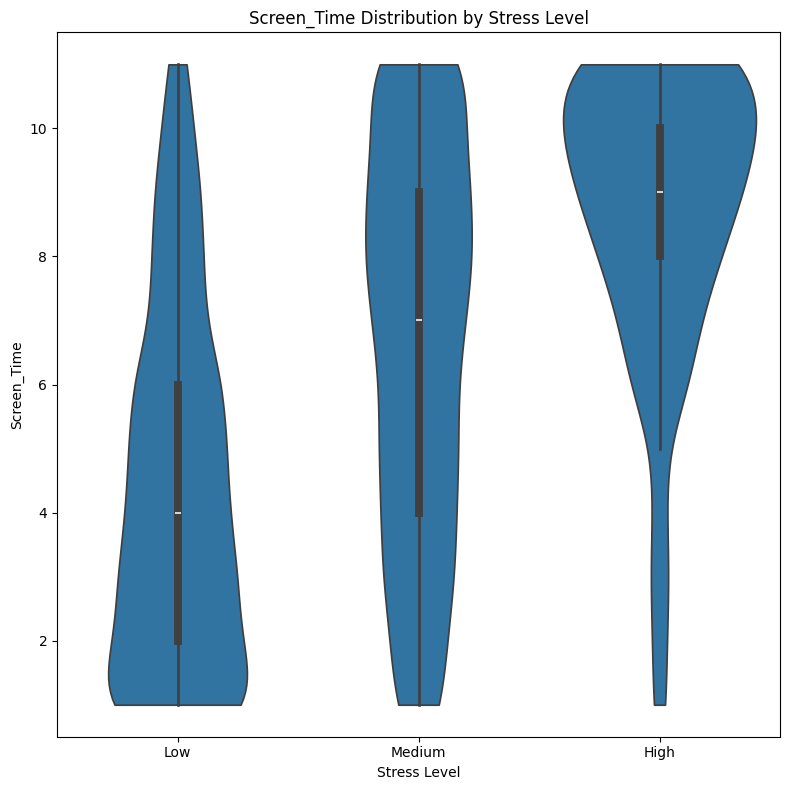

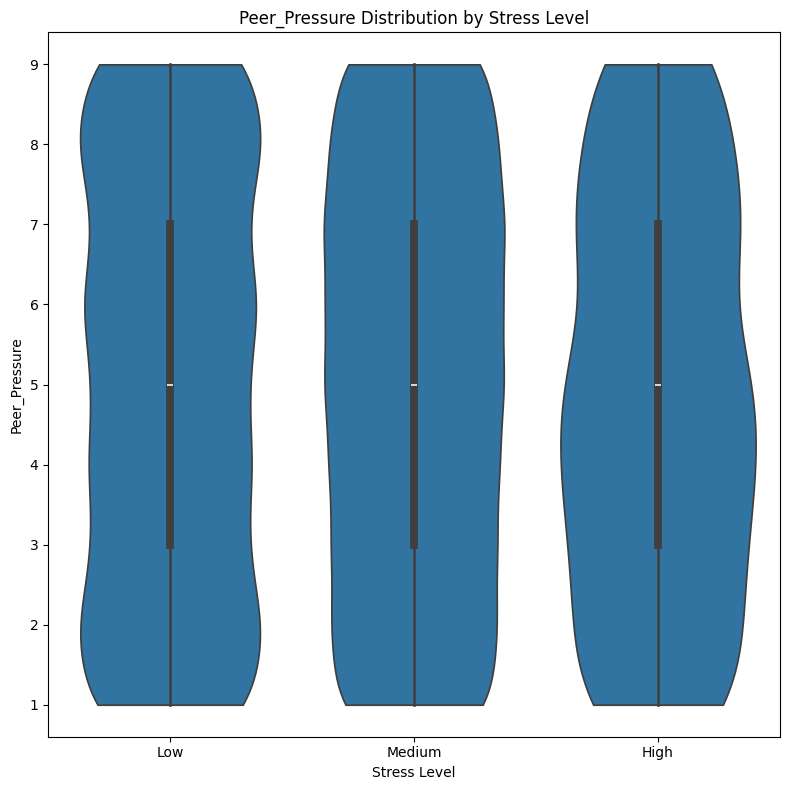

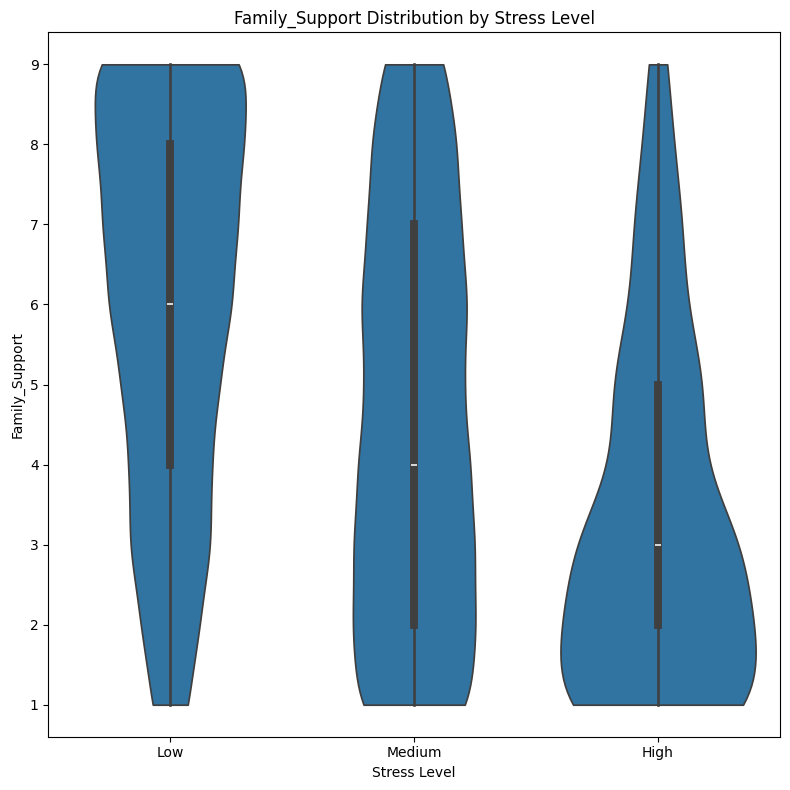

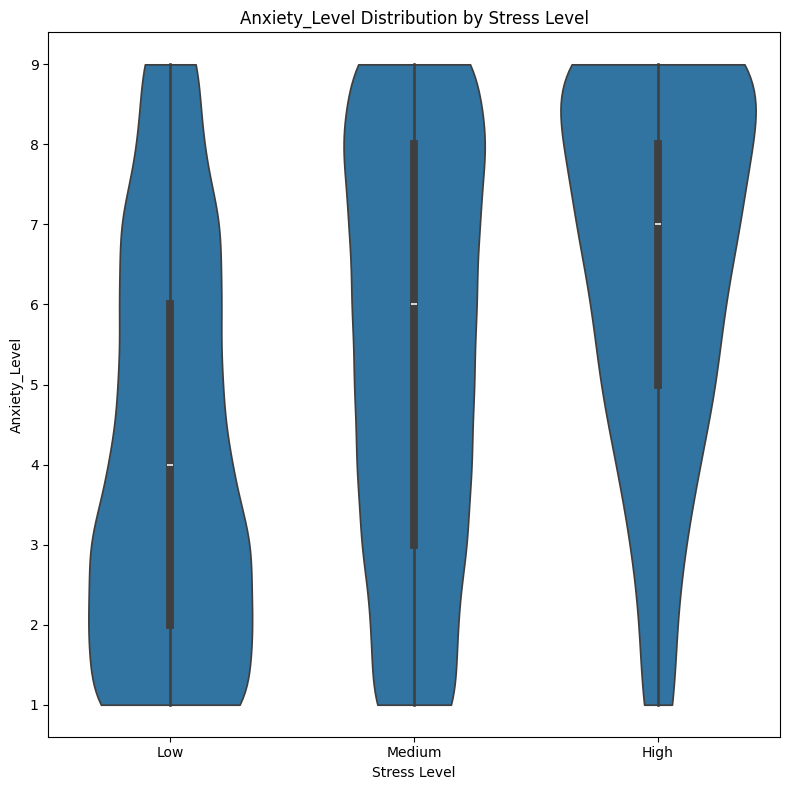

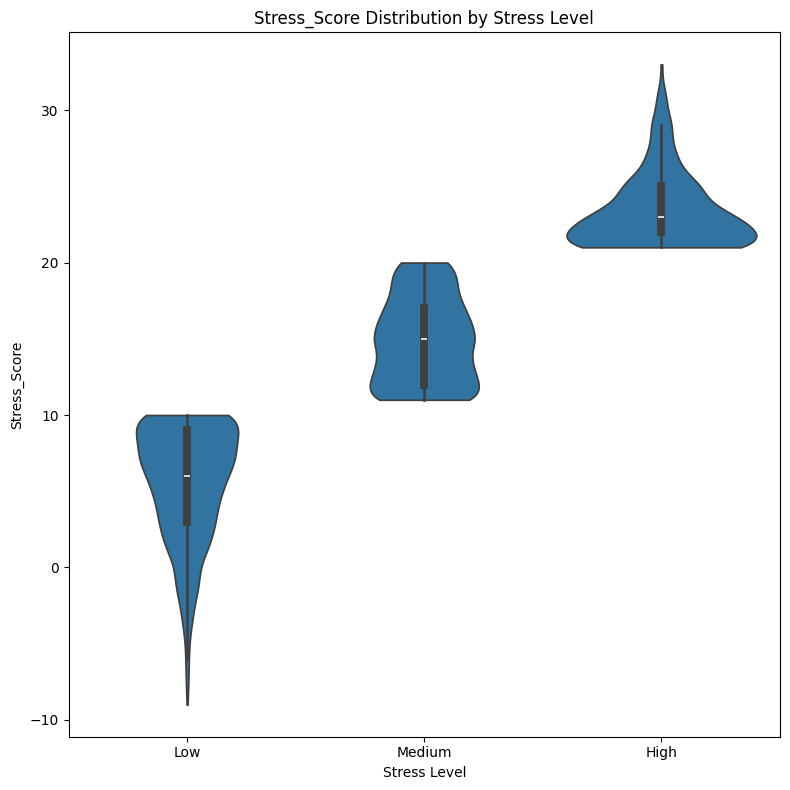

In [ ]:
stress_order = ['Low', 'Medium', 'High']

# Generate a violin plot for each numerical feature grouped by the ordered stress levels
for feature in numerical_features:
    plt.figure(figsize=(8, 8))

    sns.violinplot(
        data=df,
        x="Stress_Level",
        y=feature,
        order=stress_order,  # Enforces logical low-to-high ordering on the x-axis
        inner="box",
        cut=0
    )

    plt.title(f"{feature} Distribution by Stress Level")
    plt.xlabel("Stress Level")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

- **Clear separation (the stress groups sit at different heights):** `Exam_Frequency`, `Assignment_Load`, `Social_Media_Use`, `Screen_Time` and `Anxiety_Level` all sit higher for High stress. `Sleep_Hours` and `Family_Support` sit lower. `Screen_Time` shows the strongest shift, with High-stress students concentrated near 8 to 10 hours.
- **Almost no separation:** `Age`, `Study_Hours`, `Class_Attendance` and `Peer_Pressure` look nearly the same in all three groups, so they carry little signal on their own.
- **`Stress_Score`:** the three groups barely overlap, which is expected because the label was created from the score.

Overall, the violins are wide and flat, which matches the evenly spread data seen earlier.

### 3.3.2 Boxplots to compare medians and outliers
Boxplots are useful here, to compare the median, spread, and potential outliers of each feature across the three stress groups.

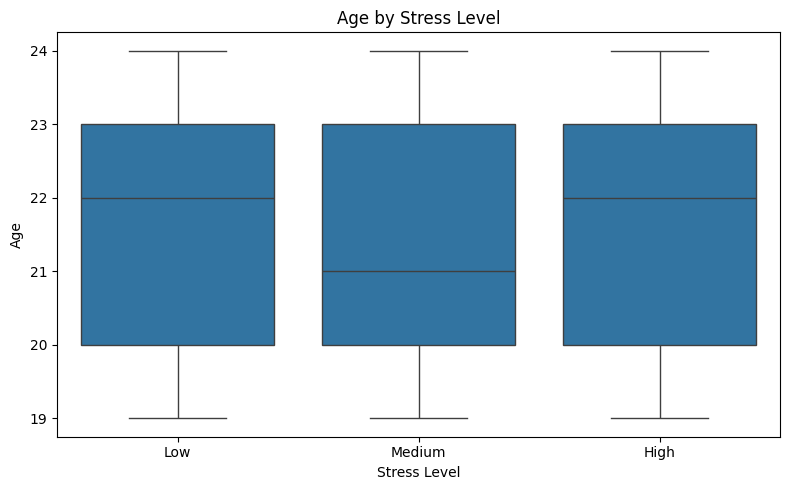

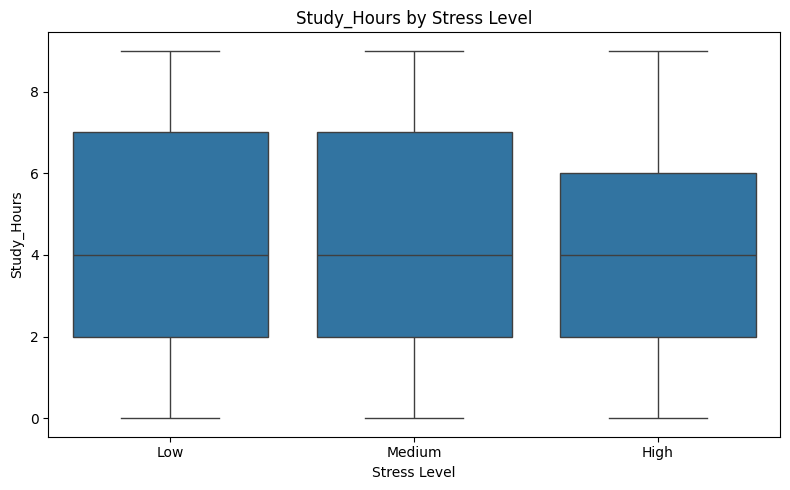

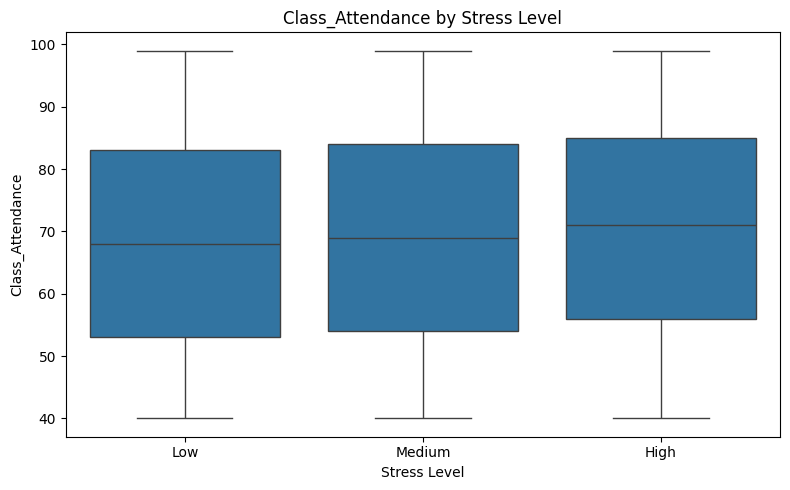

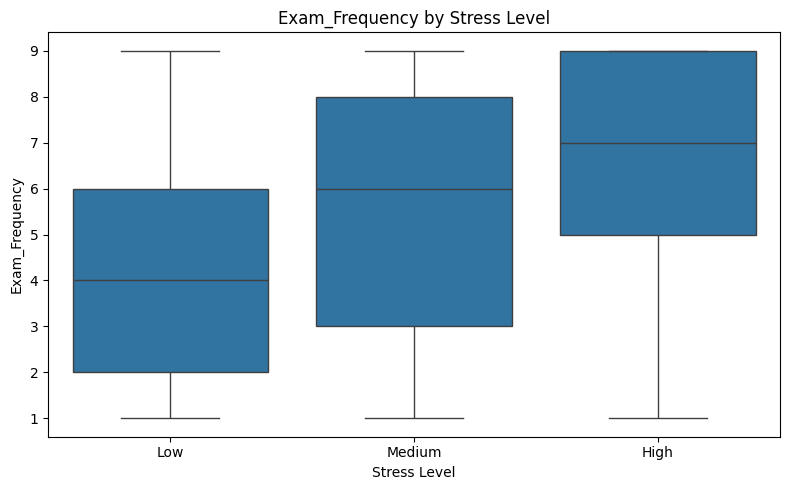

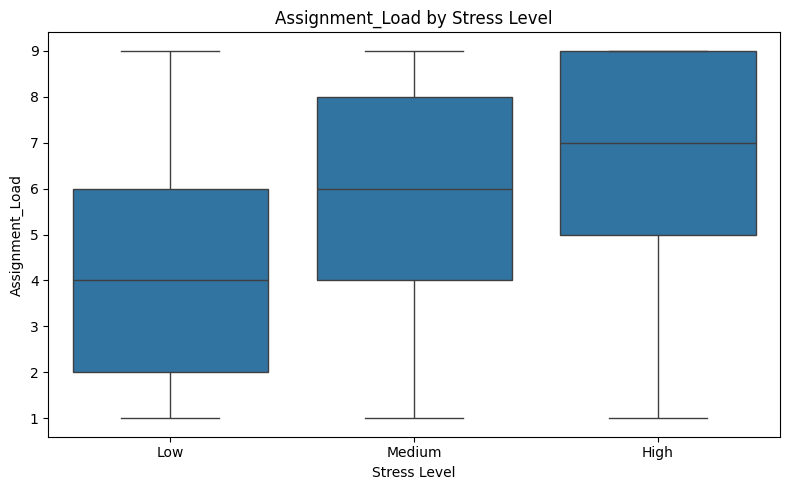

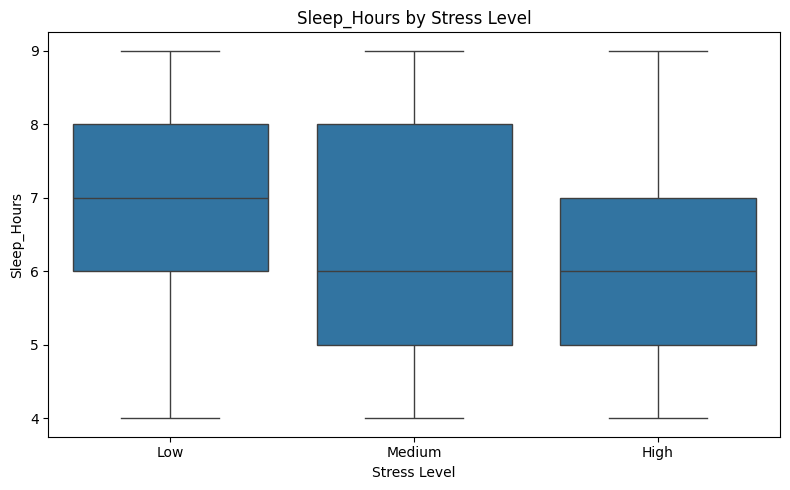

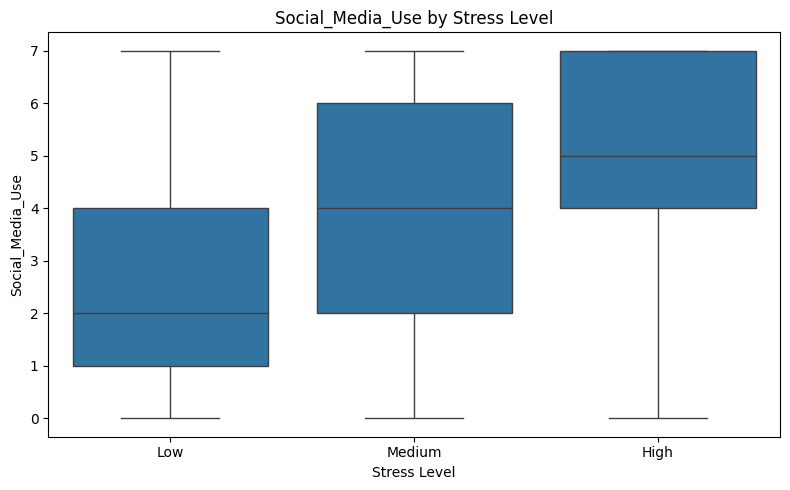

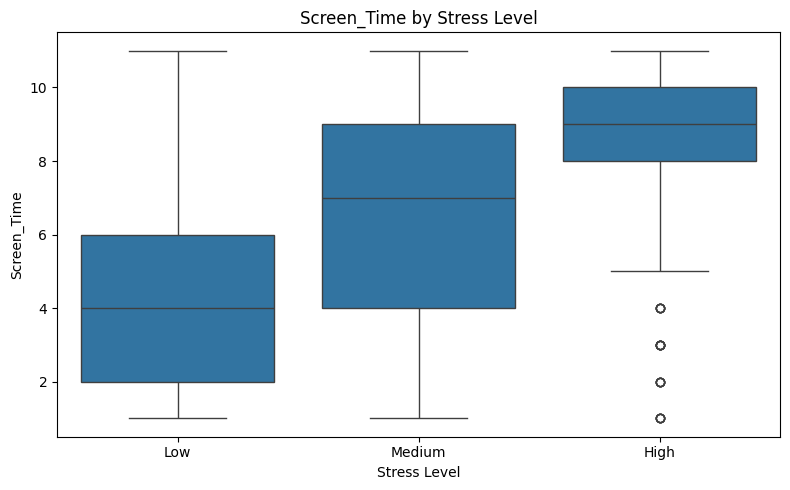

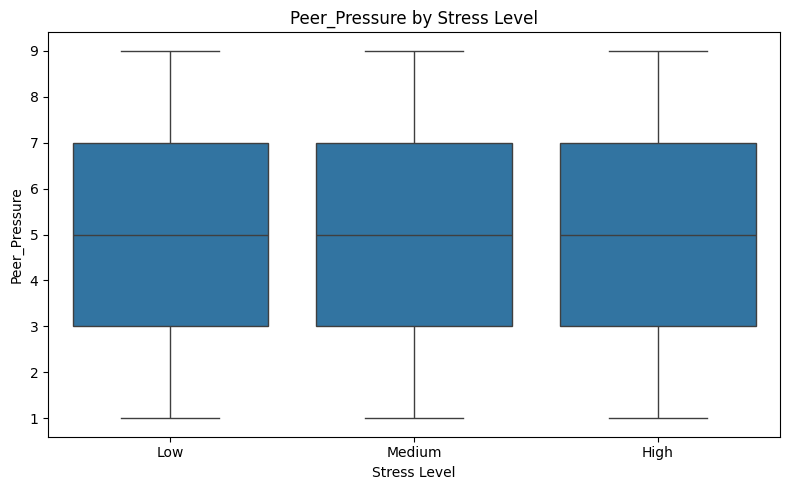

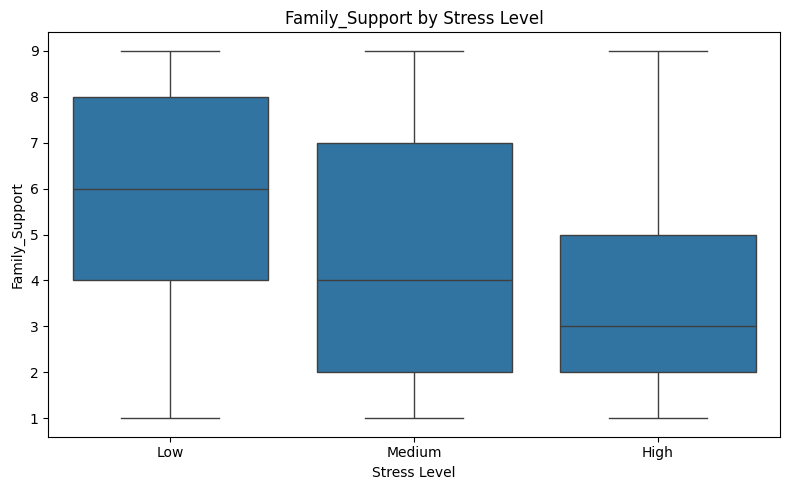

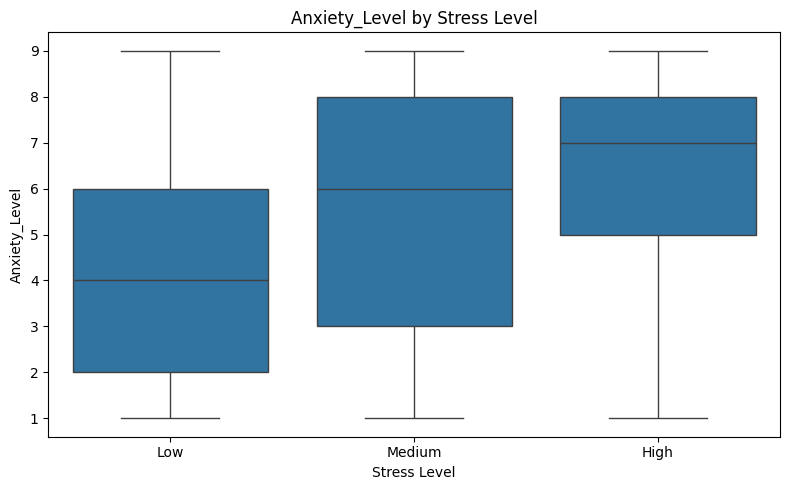

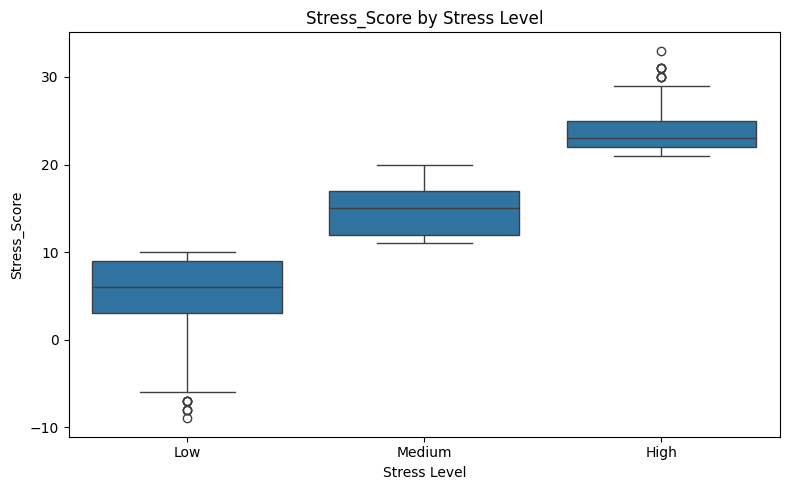

In [ ]:
# Generate box plots for each numerical feature grouped by stress level to spot medians and outliers
for feature in numerical_features:
    plt.figure(figsize=(8, 5))

    sns.boxplot(data=df, x="Stress_Level", y=feature, order=stress_order)

    plt.title(f"{feature} by Stress Level")
    plt.xlabel("Stress Level")
    plt.ylabel(feature)
    plt.tight_layout()
    plt.show()

The boxplots give the same message as the violins but in numbers we can read off. The median goes up from Low to Medium to High for these columns: `Exam_Frequency` (4, 6, 7), `Assignment_Load` (4, 6, 7), `Social_Media_Use` (2, 4, 5), `Screen_Time` (4, 7, 9) and `Anxiety_Level` (4, 6, 7). It goes down for `Sleep_Hours` (7, 6, 6) and `Family_Support` (6, 4, 3). The medians of `Age`, `Study_Hours`, `Class_Attendance` and `Peer_Pressure` are essentially unchanged, so these are weak candidates as predictors. The few dots that do appear are for `Screen_Time` in the High group (a handful of low values among mostly high ones) and for `Stress_Score`. These are natural variation rather than errors and should be kept.

### 3.3.3. Count plots to compare categorical features vs. stress level
These charts compare how many students in each category fall into each stress group.

In [ ]:
cat_df.columns

Index(['Gender', 'Tuition', 'Physical_Exercise', 'Family_Income_Level',
       'University_Type', 'Stress_Level'],
      dtype='object')

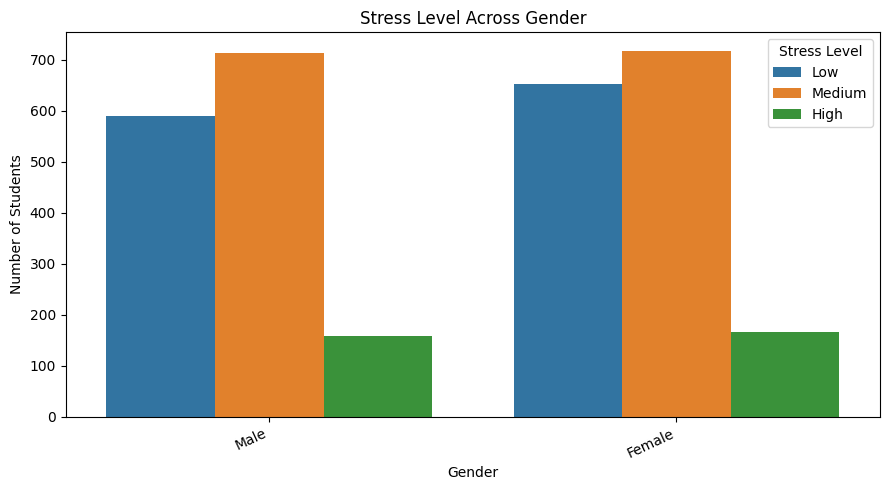

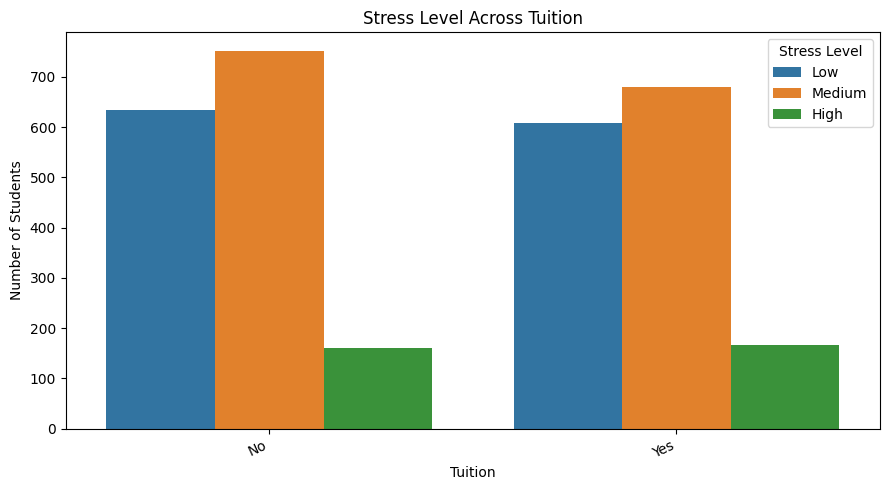

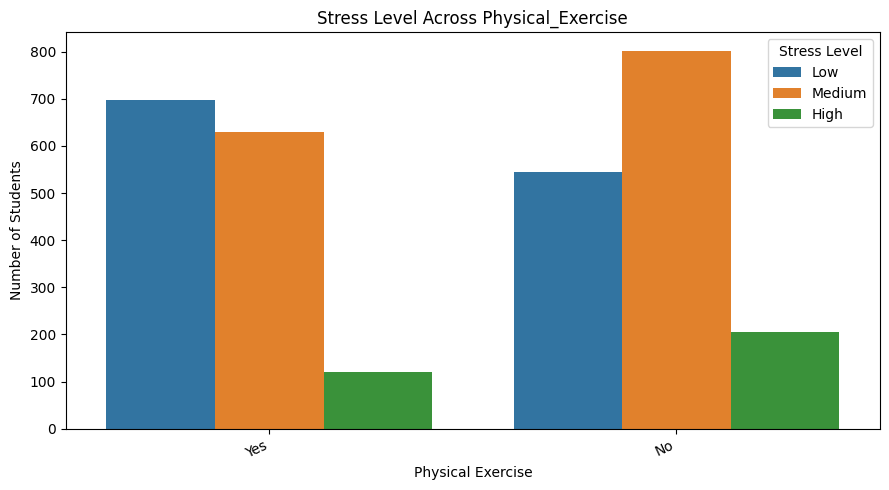

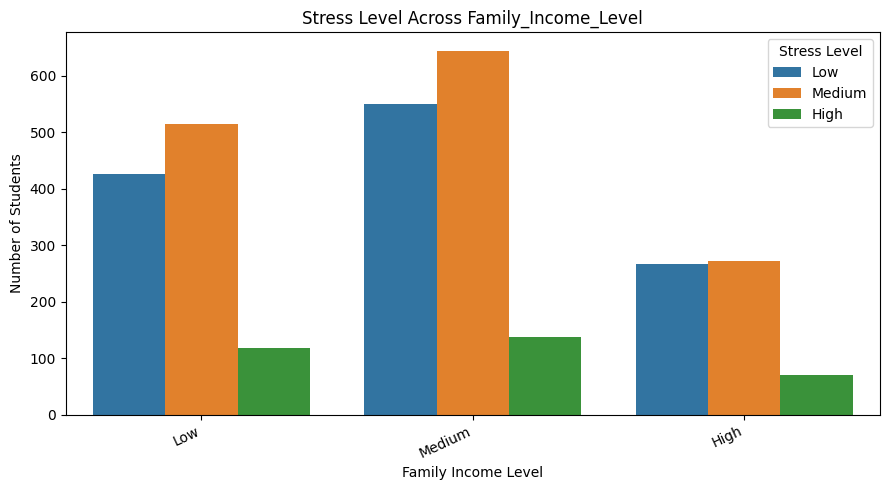

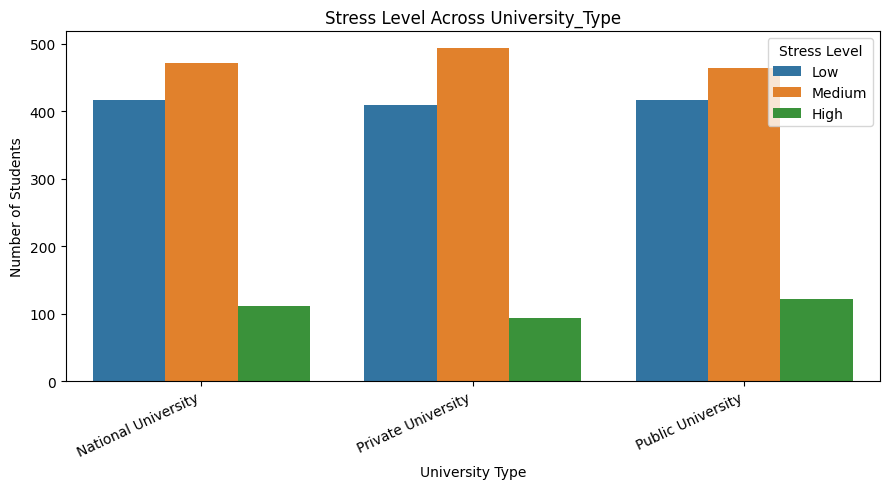

In [ ]:
# Analyze the distribution of each categorical feature broken down by Stress Level
for feature in cat_df:
    # Skip comparing Stress_Level against itself
    if feature == 'Stress_Level':
        continue

    plt.figure(figsize=(9, 5))

    sns.countplot(
        data=df,
        x=feature,
        hue="Stress_Level",
        hue_order=stress_order
    )

    plt.title(f"Stress Level Across {feature}")
    plt.xlabel(feature.replace("_", " "))
    plt.ylabel("Number of Students")
    plt.xticks(rotation=25, ha="right")
    plt.legend(title="Stress Level")
    plt.tight_layout()
    plt.show()

Each plot compares how Low, Medium and High stress are split inside every category.

- **`Physical_Exercise` shows the clearest pattern.** Students who exercise have more Low than Medium (about 700 against 630) and the fewest High (about 120). Students who do not exercise are mostly Medium (about 800), with more High (about 205).
- **`Gender`, `Tuition`, `University_Type`:** the three bars look alike in every category, so these show little or no relationship with stress.
- **`Family_Income_Level`:** the overall shape is similar for each income level. The High income group is smaller overall, but its split looks much like the others.
- **Last panel:** this plots `Stress_Level` against itself, so it only repeats the class counts. It adds no information and the legend warning above comes from this panel, so it can be dropped.

### 3.3.4 Line plots to show stress-level proportions across numerical values
A line chart is most meaningful when the x-axis has an order. Here the data will group selected numerical features into ranges and plots the percentage of students in each stress category.

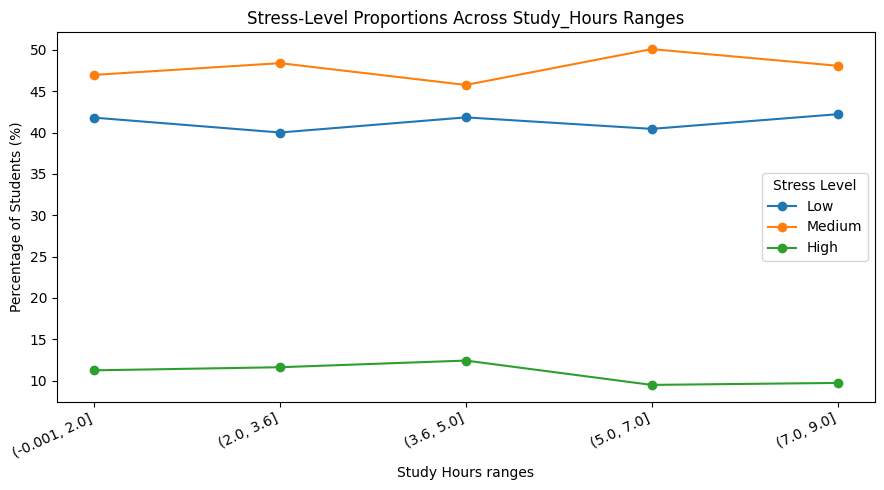

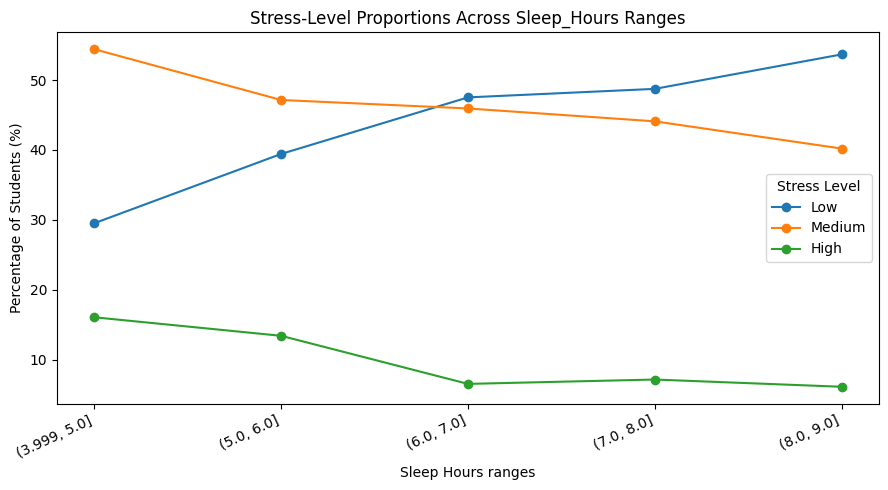

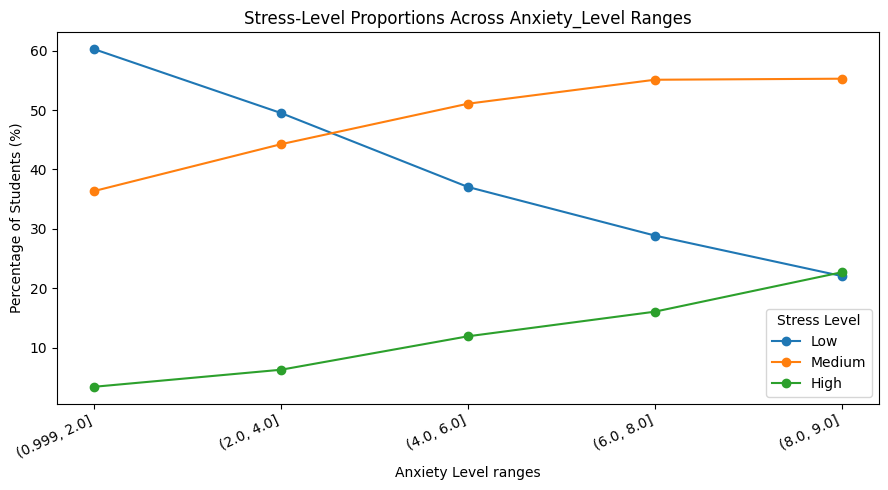

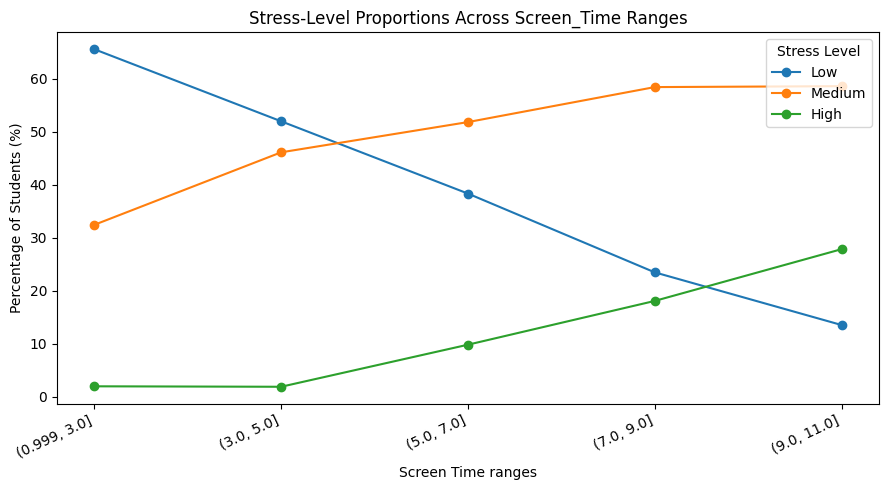

In [ ]:
trend_features = ["Study_Hours", "Sleep_Hours", "Anxiety_Level", "Screen_Time"]

for feature in trend_features:
    temp = df[[feature, "Stress_Level"]].copy()

    # Divide the continuous feature into up to five quantile-based groups
    temp["Feature_Group"] = pd.qcut(temp[feature], q=5, duplicates="drop")

    # Calculate percentage distribution of each stress level within each feature group
    proportions = (pd.crosstab(temp["Feature_Group"], temp["Stress_Level"], normalize="index").reindex(columns=stress_order, fill_value=0) * 100)

    proportions.index = proportions.index.astype(str)

    plt.figure(figsize=(9, 5))

    for level in stress_order:
        plt.plot(proportions.index, proportions[level], marker="o", label=level)

    plt.title(f"Stress-Level Proportions Across {feature} Ranges")
    plt.xlabel(f"{feature.replace('_', ' ')} ranges")
    plt.ylabel("Percentage of Students (%)")
    plt.xticks(rotation=25, ha="right")
    plt.legend(title="Stress Level")
    plt.tight_layout()
    plt.show()

Each line shows what percentage of students in a value range fall in each stress level. A line that moves a lot means the feature is related to stress.

- **`Study_Hours`:** all three lines are almost flat, so how long a student studies is not related to the stress level in this data.
- **`Sleep_Hours`:** as sleep rises from about 4 to 9 hours, Low stress climbs from about 30% to 54% and High stress drops from about 16% to 6%. More sleep goes with lower stress.
- **`Anxiety_Level`:** Low stress falls from about 60% to 22%, and High rises from about 3% to 23%. Higher anxiety goes with higher stress, as expected.
- **`Screen_Time`:** this is the steepest trend. For the lowest screen-time group about 66% have Low stress and only about 2% have High. For the highest group only about 13% are Low and about 28% are High.

## 3.4 Correlation Analysis using Heatmaps

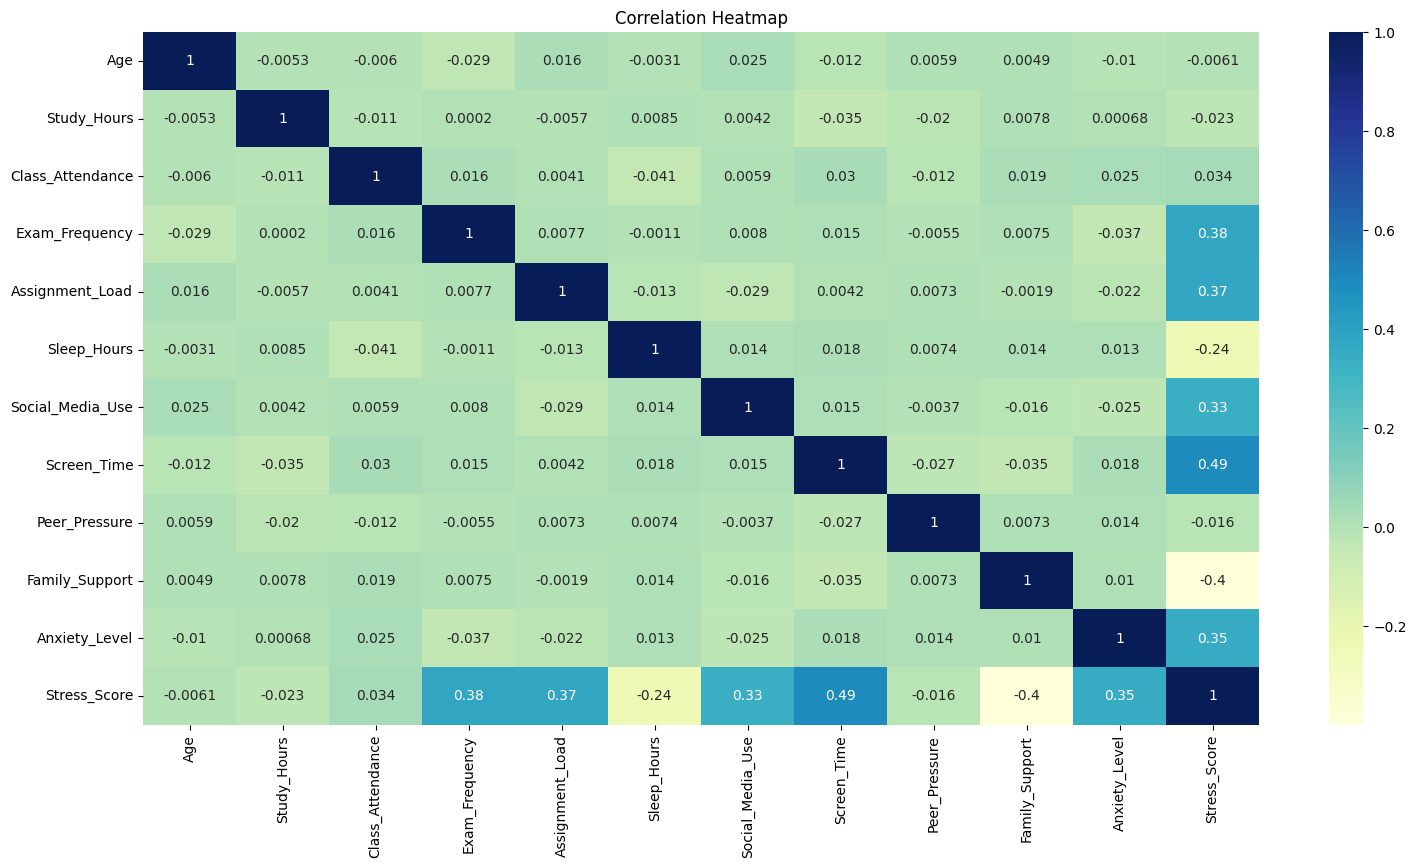

"\nnumeric_df = df.select_dtypes(include='number')\n\nplt.figure(figsize=(10, 7))\nplt.imshow(numeric_df.corr(), cmap='coolwarm')\nplt.colorbar()\nplt.xticks(range(len(numeric_df.columns)), numeric_df.columns, rotation=90)\nplt.yticks(range(len(numeric_df.columns)), numeric_df.columns)\nplt.title('Correlation Heatmap')\nplt.show()\n"

In [ ]:
# Generate a correlation matrix heatmap to check for multicollinearity among numerical features
plt.figure(figsize=(18, 9))
sns.heatmap(numerical_df.corr(), annot=True, cmap='YlGnBu')
plt.title('Correlation Heatmap')
plt.show()

'''
numeric_df = df.select_dtypes(include='number')

plt.figure(figsize=(10, 7))
plt.imshow(numeric_df.corr(), cmap='coolwarm')
plt.colorbar()
plt.xticks(range(len(numeric_df.columns)), numeric_df.columns, rotation=90)
plt.yticks(range(len(numeric_df.columns)), numeric_df.columns)
plt.title('Correlation Heatmap')
plt.show()
'''

**Interpretation:** each cell is the correlation between two columns, from -1 to +1. Values near 0 mean no linear relationship.

- **Predictors against each other are all near zero** (between about -0.04 and +0.03). No two predictors are related, there is a multicollinearity problem and no feature needs to be dropped for that reason.
- **Predictors against `Stress_Score`:** `Screen_Time` (0.49), `Family_Support` (-0.40), `Exam_Frequency` (0.38), `Assignment_Load` (0.37), `Anxiety_Level` (0.35) and `Social_Media_Use` (0.33) have the strongest links, and `Sleep_Hours` (-0.24) a moderate one. Positive means stress rises with the feature, negative means it falls.
- **No relationship:** `Age`, `Study_Hours`, `Class_Attendance` and `Peer_Pressure` are all within 0.04 of zero.

## 3.5 Statistical tests

### 1. Chi-square test of independence (categorical features vs. stress level)
**Question asked for each categorical feature:** is the stress level independent of this feature?

- **H0:** Stress level and the feature are independent.
- **H1:** They are associated.
- A p-value below 0.05 means H0 is rejected.
- The p-value says *whether* there is an association, not *how strong* it is. For strength I wii add **Cramer's V** (0 = none, about 0.1 = small, 0.3 = medium, 0.5 = large).
- The test assumes that expected counts are at least 5 in nearly all cells, which we check.
- I compare 5 features, show a Bonferroni-adjusted threshold (0.05 / 5 = 0.01).

In [ ]:
from scipy import stats

cat_features = ['Gender', 'Tuition', 'Physical_Exercise', 'Family_Income_Level', 'University_Type']

rows = []
for col in cat_features:
    # A table dipicting Stress Level as the columns then grouped by cat_features
    table = pd.crosstab(df[col], df['Stress_Level'])[stress_order]
    # The Chi-square , p-value , degree of freedom , Expected Frequency
    chi2, p, dof, expected = stats.chi2_contingency(table)
    # Sum of all values in the table
    n = table.values.sum()
    # Next, the Crammeers V formula
    cramers_v = np.sqrt(chi2 / (n * (min(table.shape) - 1)))
    # List of a dictionary. Each key is a column with its values a rows
    rows.append({'Feature': col, 'Chi2': round(chi2, 2), 'df': dof, 'p-value': p,
                 "Cramer's V": round(cramers_v, 3),
                 'Min expected count': round(expected.min(), 1),
                 'Significant (p<0.05)': p < 0.05,
                 'Significant after Bonferroni (p<0.01)': p < 0.05 / len(cat_features)})
chi_results = pd.DataFrame(rows).sort_values('p-value').reset_index(drop=True)
chi_results['p-value'] = chi_results['p-value'].map(lambda v: f'{v:.2e}')
chi_results

,Feature,Chi2,df,p-value,Cramer's V,Min expected count,Significant (p<0.05),Significant after Bonferroni (p<0.01)
0,Physical_Exercise,57.51,2,3.25e-13,0.138,157.5,True,True
1,University_Type,4.48,4,3.45e-01,0.027,108.3,False,False
2,Gender,1.48,2,4.77e-01,0.022,158.9,False,False
3,Tuition,1.44,2,4.87e-01,0.022,158.1,False,False
4,Family_Income_Level,3.15,4,5.33e-01,0.023,66.1,False,False


**Interpretation:** only `Physical_Exercise` is significantly associated with stress level (chi-square = 57.5, p about 3e-13, Cramer's V = 0.14, a small-to-moderate effect). It stays significant after the Bonferroni correction. Students who do not exercise have more High stress and less Low stress than students who do. `Gender`, `Tuition`, `Family_Income_Level` and `University_Type` all have p-values above 0.3 and Cramer's V of about 0.02, so there is no evidence that they are related to stress in this dataset. Every expected count is well above 5, so the test assumption holds.

Association is not causation, and it does not prove that exercise reduces stress.

**My Personal Note:** **(1)** Chi2=0 means theres a total independence, while > 0 means otherwise. **(2)** Crammer's V away from 0 mving towards 1 or greater shows the strength of a strong relationship.

### 2. Kruskal-Wallis test (numeric features vs. stress level)
**Why Kruskal-Wallis and not ANOVA?** The features are whole number scales with flat (uniform) distributions, so the normality assumption of ANOVA does not hold. Kruskal-Wallis compares the *ranks* of the values across the three stress groups and needs no normality assumption.

- **H0:** The feature has the same distribution in the Low, Medium and High groups of the `Stress_Level`.
- **H1:** At least one group differs.
- **Effect size:** Epsilon-squared, estimated as (H - k + 1) / (n - k), where k = 3 groups. Roughly: below 0.01 negligible, 0.01 to 0.08 small, 0.08 to 0.26 moderate, above 0.26 large.
- Because the test only says that *some* group differs, a post-hoc test (for example Dunn's test with `scikit-posthocs`) is needed to find out *which*. The boxplots from the EDA already hint at the direction.

In [ ]:
num_features = df.drop(columns=['Stress_Score']).select_dtypes('number').columns   # Exclude target/leakage column

rows = []
for col in num_features:
    # Separate the numerical feature values into distinct groups based on each stress level
    groups = [df.loc[df['Stress_Level'] == level, col] for level in stress_order]

    # Perform Kruskal-Wallis H-test (non-parametric ANOVA)
    H, p = stats.kruskal(*groups)

    # Calculate Epsilon-squared effect size for the Kruskal-Wallis test
    eps2 = (H - len(groups) + 1) / (len(df) - len(groups))

    rows.append({
                    'Feature': col,
                    'H statistic': round(H, 2),
                    'p-value': p,
                    'Epsilon-squared': round(max(eps2, 0), 3),
                    'Median Low': df.loc[df['Stress_Level'] == 'Low', col].median(),
                    'Median Medium': df.loc[df['Stress_Level'] == 'Medium', col].median(),
                    'Median High': df.loc[df['Stress_Level'] == 'High', col].median(),
                    'Significant (p<0.05)': p < 0.05
                })

kw_results = pd.DataFrame(rows).sort_values('H statistic', ascending=False).reset_index(drop=True)
kw_results['p-value'] = kw_results['p-value'].map(lambda v: f'{v:.2e}')
kw_results

,Feature,H statistic,p-value,Epsilon-squared,Median Low,Median Medium,Median High,Significant (p<0.05)
0,Screen_Time,604.28,6.05e-132,0.201,4.0,7.0,9.0,True
1,Family_Support,363.62,1.10e-79,0.121,6.0,4.0,3.0,True
2,Assignment_Load,345.49,9.50e-76,0.115,4.0,6.0,7.0,True
3,Exam_Frequency,315.63,2.89e-69,0.105,4.0,6.0,7.0,True
4,Social_Media_Use,278.61,3.17e-61,0.092,2.0,4.0,5.0,True
5,Anxiety_Level,267.40,8.59e-59,0.089,4.0,6.0,7.0,True
6,Sleep_Hours,125.87,4.66e-28,0.041,7.0,6.0,6.0,True
7,Class_Attendance,3.44,1.79e-01,0.000,68.0,69.0,71.0,False
8,Study_Hours,1.83,4.00e-01,0.000,4.0,4.0,4.0,False
9,Peer_Pressure,1.38,5.02e-01,0.000,5.0,5.0,5.0,False


**Interpretation:** seven of the eleven numeric features differ significantly across the stress groups, and the ranking by H statistic is `Screen_Time` (H = 604, the largest effect), `Family_Support`, `Assignment_Load`, `Exam_Frequency`, `Social_Media_Use`, `Anxiety_Level` and then `Sleep_Hours`. The medians move in the same direction as the plots: they rise with stress for screen time, assignments, exams, social media and anxiety, and fall for family support and sleep.

`Age`, `Study_Hours`, `Class_Attendance` and `Peer_Pressure` are not significant (p between 0.18 and 0.99, epsilon-squared about 0), so they carry no usable signal. This agrees with the correlation heatmap. These are exactly the features that are absent from the `Stress_Score` formula, so the tests recover the structure that was built into the data.

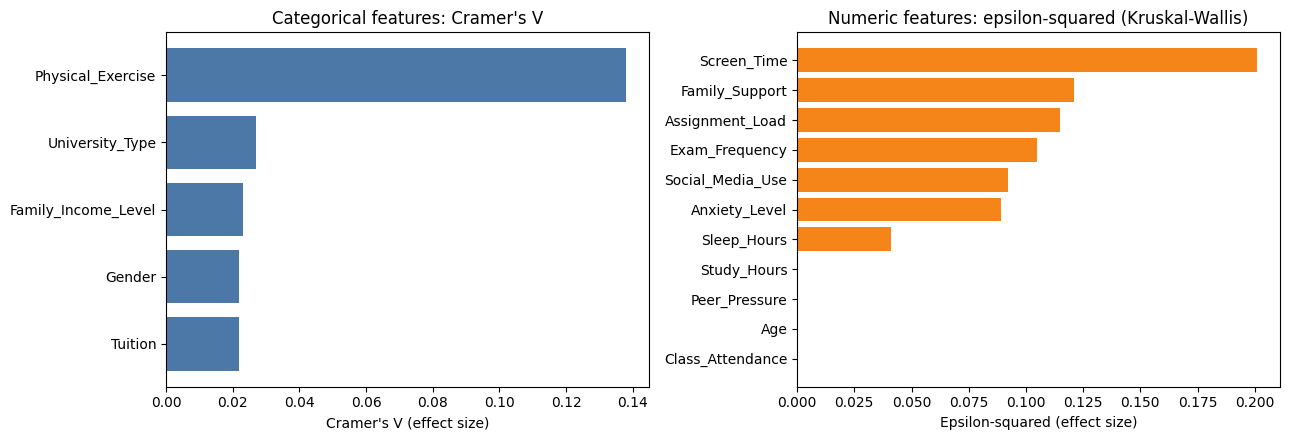

In [ ]:
# Create a side-by-side visual summary of effect sizes for both categorical and numerical features
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# Plot categorical feature effect sizes (Cramer's V)
cr = chi_results.assign(V=chi_results["Cramer's V"]).sort_values('V')
ax[0].barh(cr['Feature'], cr['V'], color='#4C78A8')
ax[0].set_title("Categorical features: Cramer's V")
ax[0].set_xlabel("Cramer's V (effect size)")

# Plot numerical feature effect sizes (Epsilon-squared)
kr = kw_results.sort_values('Epsilon-squared')
ax[1].barh(kr['Feature'], kr['Epsilon-squared'], color='#F58518')
ax[1].set_title('Numeric features: epsilon-squared (Kruskal-Wallis)')
ax[1].set_xlabel('Epsilon-squared (effect size)')

plt.tight_layout()
plt.show()

The bars show *how strong* each relationship is, which is more useful than a p-value alone (with 3,000 rows even tiny effects can be significant).

- **1.** According to the Plot on the Left (Blue Colored):
For the categorical features only `Physical_Exercise` has a visible bar.
- **2.** The Plot on the Right (Orange Colored): `Screen_Time` stands out, followed by `Family_Support`, `Assignment_Load` and `Exam_Frequency`.

# 4. Data Transformation, Model Preparation and Preprocessing

## 1. Target and Feature Selection

### Target Variable:
`Stress_Level` is the target variable

### Feature Variables:
'Age', 'Gender', 'Study_Hours', 'Class_Attendance', 'Tuition',
       'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Physical_Exercise',
       'Social_Media_Use', 'Screen_Time', 'Family_Income_Level',
       'Peer_Pressure', 'Family_Support', 'Anxiety_Level', 'University_Type'

`'Stress_Score'` is going to be dropped to avoid data laekage

## 2. Model building
**Design choices**
- `Stress_Score` is never used as an input (leakage, section 1.1).
- One **stratified 80/20 split** with a fixed seed. The same students go to train and test in every run, so every comparison is fair. All model comparison uses **5-fold cross-validation on the training part only**. The test part is used once, to report the final numbers.
- Every model sits inside a scikit-learn **Pipeline** (scaling + encoding + model).
- Metrics: **macro-F1** (treats Low, Medium and High equally, so the small High class counts) and **recall on High** (how many truly High students we catch).

**Six models are compared**

| Model | Why it is included |
|---|---|
| Dummy (always "Medium") | Baseline. Any real model must beat it. |
| Logistic Regression | Simple and inherently interpretable. |
| Decision Tree (depth 4) | Interpretable, rule-style model. |
| K-Nearest Neighbours | Distance-based model. |
| Random Forest | Strong, popular ensemble. |
| Gradient Boosting | Usually the strongest tabular black-box model. |

In [ ]:
# --- Validation & Pipeline Tools ---
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# --- Preprocessing ---
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --- Models ---
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

# --- Evaluation Metrics ---
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, f1_score, recall_score

In [ ]:
# Define feature sets for experimentation
FEATURES_ALL = [c for c in df.columns if c not in ('Stress_Score', 'Stress_Level')]  # Full feature set (16 columns)
FEATURES_8 = [
                    'Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use',
                    'Screen_Time', 'Family_Support', 'Anxiety_Level', 'Physical_Exercise'
                ]  # Refined subset selected based on previous EDA effect-size analysis

In [ ]:
# Separate features and target variable
X = df[FEATURES_ALL]
y = df['Stress_Level']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (3000, 16)
Target shape: (3000,)


## 3. Split, Train, Test and Preprocessing

The dataset will be divided into training and testing sets. The training set will be used to train the models, while the test set will be reserved for evaluating their performance on unseen observations.

In [ ]:
# Split data into training and testing sets while preserving class distribution via stratification
X_train, X_test, y_train, y_test = train_test_split(
                                                        X, y,
                                                        test_size=0.20,
                                                        stratify=y,
                                                        random_state=42
                                                    )

print("Training set shape (X, y):", X_train.shape, y_train.shape)
print("Testing set shape (X, y):", X_test.shape, y_test.shape)

Training set shape (X, y): (2400, 16) (2400,)
Testing set shape (X, y): (600, 16) (600,)


In [ ]:
print('Train size:', len(X_train), '| Test size:', len(X_test))
print("Train class proportions:", y_train.value_counts(normalize=True).round(3).to_dict())
print("Test class proportions:", y_test.value_counts(normalize=True).round(3).to_dict())

Train size: 2400 | Test size: 600
Train class proportions: {'Medium': 0.477, 'Low': 0.414, 'High': 0.109}
Test class proportions: {'Medium': 0.477, 'Low': 0.415, 'High': 0.108}


## 4. Next - Apply data preparation on training data

In [ ]:
def candidate_models():
    # Returns a dictionary of configured candidate machine learning models for stress classification, ranging from a baseline to tree ensembles.
    return {
                'Dummy (baseline)': DummyClassifier(strategy='most_frequent'),
                'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced'),
                'Decision Tree': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=42),
                'KNN': KNeighborsClassifier(n_neighbors=15),
                'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42, n_jobs=-1),
                'Gradient Boosting': HistGradientBoostingClassifier(random_state=42)
            }

### My Personal Notes on Model Parameters

- **Dummy Classifier:** `strategy='most_frequent'` always predicts the most common class. It serves as a baseline to compare other models against.
- **Logistic Regression:** `max_iter=2000` allows more iterations for the model to find a solution; `class_weight='balanced'` gives more weight to less common classes.
- **Decision Tree:** `max_depth=4` limits the tree's depth to keep it simpler; `class_weight='balanced'` helps account for class imbalance; `random_state=42` makes results reproducible.
- **KNN:** `n_neighbors=15` uses the 15 nearest training examples to decide the predicted class.
- **Random Forest:** `n_estimators=300` builds 300 decision trees; `class_weight='balanced'` accounts for class imbalance; `random_state=42` supports reproducibility; `n_jobs=-1` uses all available CPU cores.
- **Gradient Boosting:** `random_state=42` helps make results reproducible. `HistGradientBoostingClassifier` builds trees sequentially to improve predictions from earlier trees.

In [ ]:
def compare_models(cols):
    """Trains and evaluates candidate models using stratified cross-validation
    and a held-out test set, returning a performance comparison DataFrame
    and a dictionary of fitted pipelines.
    """
    # Automatically separate features into categorical and numerical subsets
    cat = [c for c in cols if not pd.api.types.is_numeric_dtype(df[c])]
    num = [c for c in cols if c not in cat]

    # Cross Validation (Low,Medium,High) will be splited equally
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42) # Splits the data into 5 folds

    rows = []
    fitted = {}

    for name, model in candidate_models().items():
        # Bundle preprocessing and model into a leakage-safe pipeline
        preprocessor = ColumnTransformer([
                                                ("num", StandardScaler(), num),
                                                ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), cat)
                                            ])

        pipe = Pipeline([
                            ("prep", preprocessor),
                            ("model", model)
                        ])

        # Evaluate cross-validation performance on the training set
        cvs = cross_val_score(pipe, X_train[cols], y_train, cv=cv, scoring="f1_macro")

        # Fit on the full training set and predict on the test set
        pipe.fit(X_train[cols], y_train)
        pred = pipe.predict(X_test[cols])

        fitted[name] = pipe

        # Record evaluation metrics across cross-validation and test sets
        rows.append({
                        "Model": name,
                        "CV macro-F1": round(cvs.mean(), 3),
                        "CV std": round(cvs.std(), 3),
                        "Test macro-F1": round(f1_score(y_test, pred, average="macro"), 3),
                        "Test recall (High)": round(recall_score(y_test, pred, labels=["High"], average=None, zero_division=0)[0], 3),
                        "Test accuracy": round((pred == y_test).mean(), 3)
                    })

    return pd.DataFrame(rows), fitted

## 4.1 First: Run all 16 features

In [ ]:
table_16, pipes_16 = compare_models(FEATURES_ALL)

In [ ]:
pipes_16

{'Dummy (baseline)': Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['Age', 'Study_Hours',
                                                    'Class_Attendance',
                                                    'Exam_Frequency',
                                                    'Assignment_Load',
                                                    'Sleep_Hours',
                                                    'Social_Media_Use',
                                                    'Screen_Time',
                                                    'Peer_Pressure',
                                                    'Family_Support',
                                                    'Anxiety_Level']),
                                                  ('cat',
                                                   OneHotEncoder(drop='if_binary',
                                  

In [ ]:
table_16

,Model,CV macro-F1,CV std,Test macro-F1,Test recall (High),Test accuracy
0,Dummy (baseline),0.215,0.000,0.215,0.000,0.477
1,Logistic Regression,0.968,0.009,0.979,1.000,0.988
2,Decision Tree,0.565,0.012,0.572,0.615,0.607
3,KNN,0.721,0.027,0.737,0.338,0.828
4,Random Forest,0.716,0.037,0.706,0.262,0.818
5,Gradient Boosting,0.847,0.013,0.841,0.600,0.880


### Interpretation of Model Comparison Results

`Logistic Regression` performed best, achieving a test macro-F1 score of 0.979 and an accuracy of 98.8%, with a High stress recall of 100%. `Gradient Boosting` was the second-best model, with a test macro-F1 of 0.841 and accuracy of 88.0%. `KNN` and `Random Forest` achieved reasonable accuracy but struggled to identify students in the High stress category. The `Decision Tree` performed moderately, while the `Dummy Classifier` provided a baseline for comparison. Overall, `Logistic Regression` is the strongest candidate based on these results.

**My Personal Note**

**1. CV macro-F1:** The average macro-F1 score across cross-validation folds, giving equal weight to all classes to measure balance between precision and recall. Range: 0.0-1.0 where 1.0 is a perfect score and indicates a strong, stable performance (and < 0.5 = model is struggling).

**2. CV std:** The standard deviation of the cross-validation scores, indicating how much the model's performance varied across the different folds (lower value mean higher stability). Range: 0.0 upward (b/w 0.00 and 0.10 for stable model)

**3. Test macro-F1:** The macro-F1 score calculated on the held-out test, showing how well the model generalizes to unseen data across all classes. Range: 0.0-1.0 where 1.0 is a perfect score (and < 0.5 = model is struggling). Low scores that drop drastically compared to CV macro-F1 score indicates overfitting (the model memorized training data but fails on new data).

**4. Test recall(High):** The recall (true postive rate) specifically for the "High" class on the test set, measuring how many of the actual"High" instances the model successfully caught. Range: 0.0-1.0 (High values are better e.g 1.0 or 100%)

**5. Test acuracy:** The overall proportion of the coreect predictions across all classes on the test set. Range: 0.0-1.0 (High values are better e.g 1.0 or 100%)

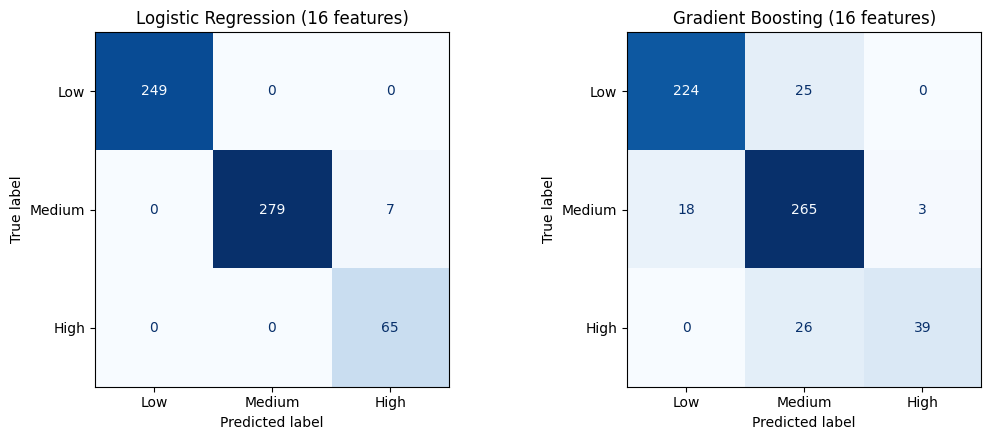

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       249
      Medium       1.00      0.98      0.99       286
        High       0.90      1.00      0.95        65

    accuracy                           0.99       600
   macro avg       0.97      0.99      0.98       600
weighted avg       0.99      0.99      0.99       600



In [ ]:
# Plot side-by-side confusion matrices for key models using the full 16-feature set
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, name in zip(axes, ["Logistic Regression", "Gradient Boosting"]):
    y_pred = pipes_16[name].predict(X_test[FEATURES_ALL])
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=stress_order, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name} (16 features)")

plt.tight_layout()
plt.show()

# Generate a detailed classification report for Logistic Regression
y_pred_lr = pipes_16["Logistic Regression"].predict(X_test[FEATURES_ALL])
print(classification_report(y_test, y_pred_lr, labels=stress_order, zero_division=0))

Looking at the results together, Logistic Regression performed best across all the reported evaluation metrics. It achieved the highest cross-validation macro-F1, the highest test macro-F1, the highest High stress recall, and the highest test accuracy. Its low cross-validation standard deviation also suggests that its performance was consistent across the validation folds.

Gradient Boosting came second based on test macro-F1, followed by KNN, Random Forest, Decision Tree, and the Dummy Classifier. However, the models do not perform equally well on every class. For example, KNN and Random Forest achieved test accuracies above 80%, but their recall for High stress was much lower. This shows that overall accuracy alone can hide weaknesses in the classification of particular categories.

The Dummy Classifier provides a useful reference point. The other models generally performed better than this baseline, but the size of the improvement varied. Logistic Regression showed a particularly large improvement, while the Decision Tree achieved a more modest one.

Based on these results, Logistic Regression is the leading candidate for the next stage of the project. Gradient Boosting is also worth keeping as a comparison model because it achieved good overall performance and better High stress recall than KNN and Random Forest.

Before making a final decision, I should inspect the confusion matrices and classification reports, especially the precision and recall for each stress category. I should also confirm that the test set has not been used repeatedly to choose models or tune their parameters.

### Visualization of: Actual Vs Predicted Values for the 16 Columns training features used

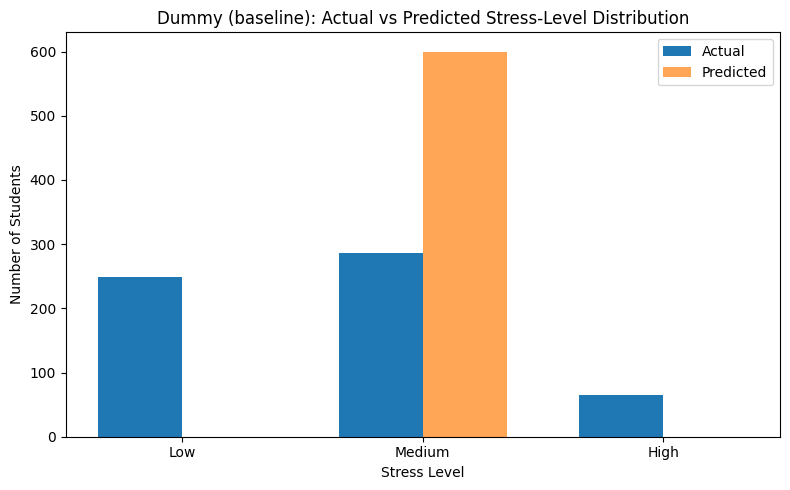

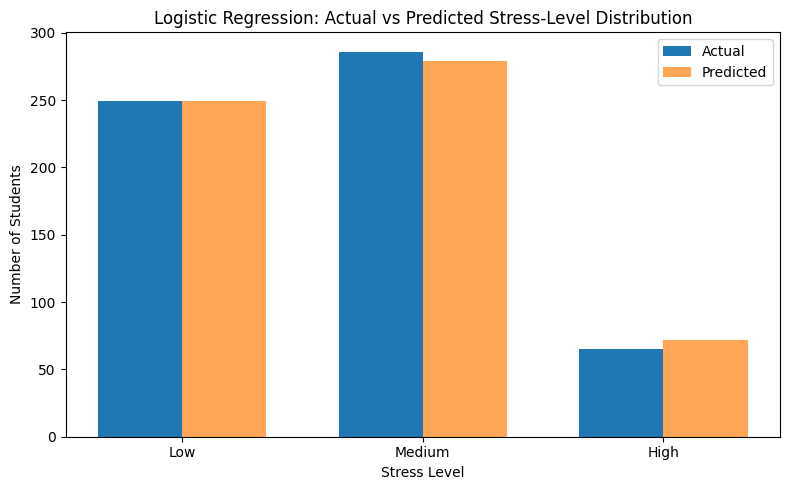

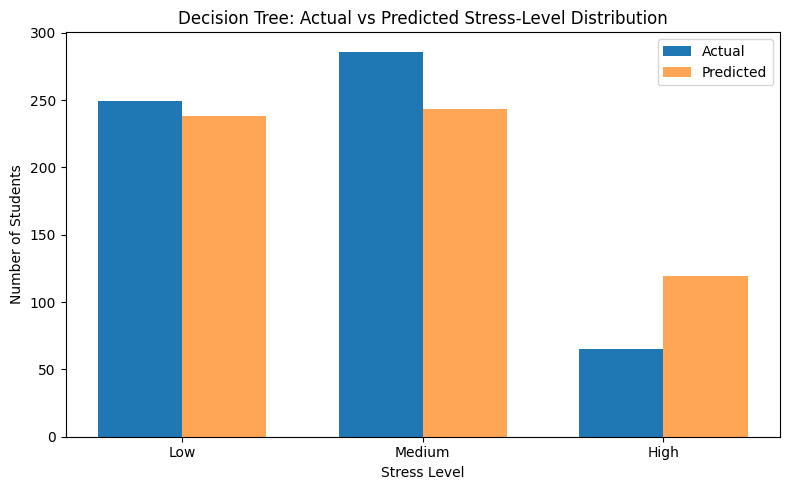

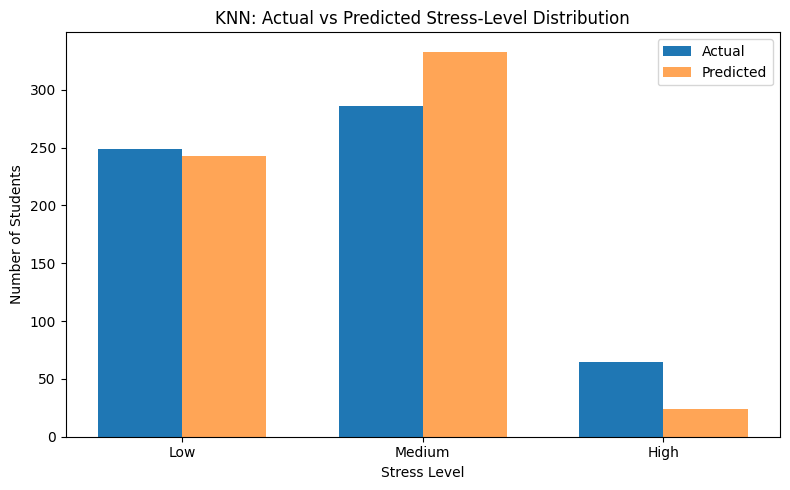

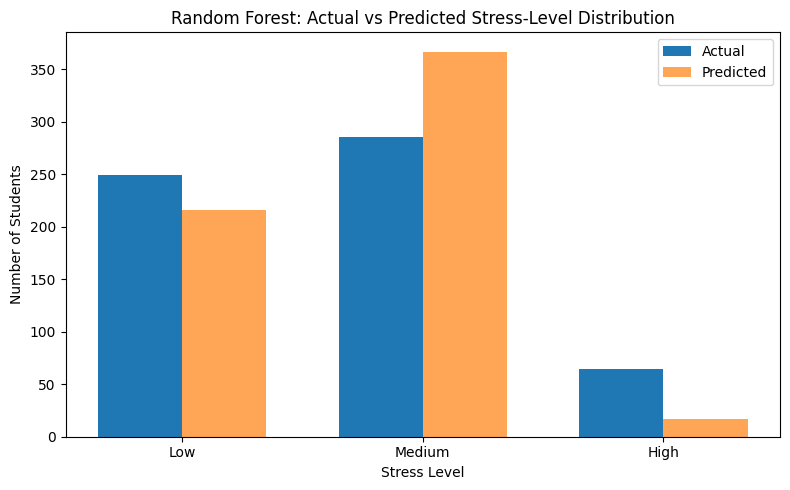

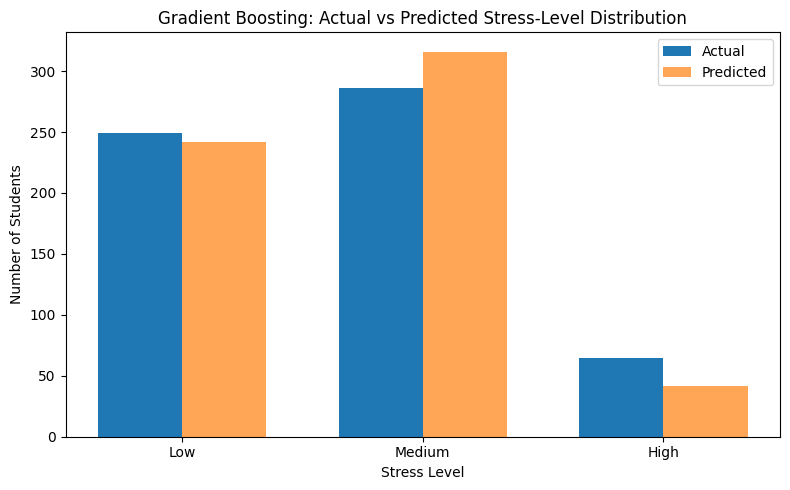

In [ ]:
stress_order = ["Low", "Medium", "High"]

for name, model in pipes_16.items():

    # Predict stress levels on the test set
    pred = model.predict(X_test[FEATURES_ALL])

    # Count actual and predicted cases in the same category order
    actual_counts = y_test.value_counts().reindex(stress_order, fill_value=0)
    predicted_counts = (pd.Series(pred).value_counts().reindex(stress_order, fill_value=0))

    x = np.arange(len(stress_order))
    width = 0.35

    plt.figure(figsize=(8, 5))

    plt.bar(x - width / 2, actual_counts.values, width, label="Actual")

    plt.bar(x + width / 2, predicted_counts.values, width, label="Predicted", alpha=0.7)

    plt.xticks(x, stress_order)
    plt.xlabel("Stress Level")
    plt.ylabel("Number of Students")
    plt.title(f"{name}: Actual vs Predicted Stress-Level Distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Which of the 16 features does the best model use?

In [ ]:
# Displaying Models and Preprocessors
Logistic = pipes_16['Logistic Regression']
display(Logistic)

display('Model:' , Logistic.named_steps['model'])
display('Model_Coefficients:' , Logistic.named_steps['model'].coef_)

display('Preprocessors:' , Logistic.named_steps['prep'])
display('Preprocessed Feature Names:' , Logistic.named_steps['prep'].get_feature_names_out())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

'Model:'

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

'Model_Coefficients:'

array([[-6.02406239e-02, -8.38197471e-03,  6.08587699e-02,
         3.85122852e+00,  3.98847956e+00, -2.40257902e+00,
         3.53401407e+00,  4.80519599e+00, -4.46038047e-02,
        -3.93609278e+00,  3.91131249e+00, -2.30155327e-03,
         1.48813589e-01, -2.83860635e+00,  3.38690970e-02,
         4.25642764e-03, -1.15386273e-01, -1.10049802e-01,
         1.62549010e-01, -1.29759955e-01],
       [ 3.13044231e-02,  3.24595246e-02, -4.74998708e-02,
        -3.93949450e+00, -3.97470900e+00,  2.47758206e+00,
        -3.52052660e+00, -4.82853768e+00,  5.55186975e-02,
         3.91409381e+00, -3.93726351e+00, -3.26692878e-02,
        -6.94215800e-02,  2.89356655e+00,  2.33417748e-02,
        -7.44491354e-03,  7.94292525e-02,  7.03759694e-02,
        -1.48228159e-01,  1.73178303e-01],
       [ 2.89362008e-02, -2.40775499e-02, -1.33588990e-02,
         8.82659824e-02, -1.37705608e-02, -7.50030370e-02,
        -1.34874619e-02,  2.33416822e-02, -1.09148928e-02,
         2.19989668e-02,  2.5

'Preprocessors:'

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

'Preprocessed Feature Names:'

array(['num__Age', 'num__Study_Hours', 'num__Class_Attendance',
       'num__Exam_Frequency', 'num__Assignment_Load', 'num__Sleep_Hours',
       'num__Social_Media_Use', 'num__Screen_Time', 'num__Peer_Pressure',
       'num__Family_Support', 'num__Anxiety_Level', 'cat__Gender_Male',
       'cat__Tuition_Yes', 'cat__Physical_Exercise_Yes',
       'cat__Family_Income_Level_High', 'cat__Family_Income_Level_Low',
       'cat__Family_Income_Level_Medium',
       'cat__University_Type_National University',
       'cat__University_Type_Private University',
       'cat__University_Type_Public University'], dtype=object)

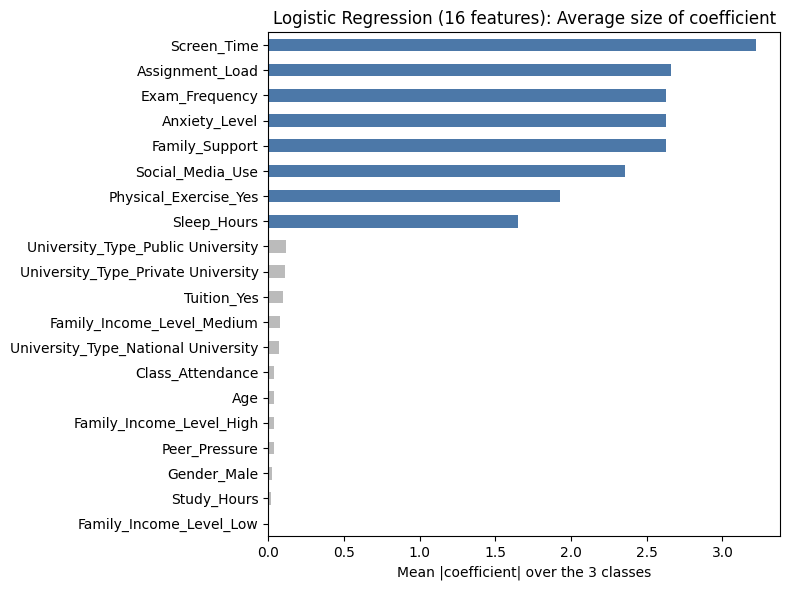

In [ ]:
# Extract the trained Logistic Regression pipeline for the 16-feature set
lr16 = pipes_16['Logistic Regression']

# Clean up feature names by stripping out the ColumnTransformer prefixes (e.g., 'num__', 'cat__')
names16 = [n.split('__')[1] for n in lr16.named_steps['prep'].get_feature_names_out()]

# Compute the mean absolute coefficient across the 3 classes to gauge overall feature importance
w = pd.Series(np.abs(lr16.named_steps['model'].coef_).mean(axis=0), index=names16).sort_values()

# Plot horizontal bar chart with conditional coloring for prominent features
w.plot.barh(figsize=(8, 6), color=['#4C78A8' if v > 0.5 else '#BBBBBB' for v in w])
plt.title('Logistic Regression (16 features): Average size of coefficient')
plt.xlabel('Mean |coefficient| over the 3 classes')
plt.tight_layout()
plt.show()

**Interpretation:** This chart ranks the 16 features by their overall influence on the multi-class Logistic Regression model.

* **Metric (`Mean |coefficient| over the 3 classes`)**: It calculates the absolute value of **coefficients** ensuring positive and negative impacts are measured equally by magnitude and averages them across all 3 target classes.
* The chart suggests that the 8 features with larger coefficients contribute more to the Logistic Regression model's predictions, while the other 8 have very small coefficients. These less influential features also appear to have little relationship with stress in the earlier statistical tests and are not part of the formula used to calculate Stress_Score. This gives a reason to test a smaller feature set, but it does not prove these features are useless in every model. One should compare model performance with and without them before deciding to drop them.

**Coefficient** here represents the learned weight or multiplier assigned by the Logistic Regression during training. They are numerical values that a mchine learning model adjusts automatically as it learns from data.

## 4.2 Finally: Run the 8 selected features

In [ ]:
table_8, pipes_8 = compare_models(FEATURES_8)

In [ ]:
pipes_8

{'Dummy (baseline)': Pipeline(steps=[('prep',
                  ColumnTransformer(transformers=[('num', StandardScaler(),
                                                   ['Exam_Frequency',
                                                    'Assignment_Load',
                                                    'Sleep_Hours',
                                                    'Social_Media_Use',
                                                    'Screen_Time',
                                                    'Family_Support',
                                                    'Anxiety_Level']),
                                                  ('cat',
                                                   OneHotEncoder(drop='if_binary',
                                                                 handle_unknown='ignore'),
                                                   ['Physical_Exercise'])])),
                 ('model', DummyClassifier(strategy='most_frequent'))]),
 'Logis

In [ ]:
table_8

,Model,CV macro-F1,CV std,Test macro-F1,Test recall (High),Test accuracy
0,Dummy (baseline),0.215,0.000,0.215,0.000,0.477
1,Logistic Regression,0.966,0.011,0.976,1.000,0.987
2,Decision Tree,0.565,0.012,0.572,0.615,0.607
3,KNN,0.821,0.031,0.796,0.446,0.865
4,Random Forest,0.797,0.026,0.786,0.415,0.860
5,Gradient Boosting,0.863,0.016,0.846,0.631,0.878


### Interpretation of Model Comparison After Feature Selection

After selecting the 8 most important features and removing the less influential ones, I retrained the models to see how feature selection affected their performance. `Logistic Regression` remained the best-performing model, with a test macro-F1 of 0.976 and accuracy of 98.7%, showing almost no decline from the original results. `Gradient Boosting` improved slightly in macro-F1 to 0.846, while `KNN` and `Random Forest` also recorded better overall performance. However, their recall for the High stress category remained relatively low. The `Decision Tree's` performance stayed unchanged, while the `Dummy Classifier` continued to serve as the baseline. Overall, reducing the features maintained strong performance for `Logistic Regression` and improved some of the other models. This suggests that the selected features may be sufficient for classification on this dataset.

**My Personal Note**

**1. CV macro-F1:** The average macro-F1 score across cross-validation folds, giving equal weight to all classes to measure balance between precision and recall. Range: 0.0-1.0 where 1.0 is a perfect score and indicates a strong, stable performance (and < 0.5 = model is struggling).

**2. CV std:** The standard deviation of the cross-validation scores, indicating how much the model's performance varied across the different folds (lower value mean higher stability). Range: 0.0 upward (b/w 0.00 and 0.10 for stable model)

**3. Test macro-F1:** The macro-F1 score calculated on the held-out test, showing how well the model generalizes to unseen data across all classes. Range: 0.0-1.0 where 1.0 is a perfect score (and < 0.5 = model is struggling). Low scores that drop drastically compared to CV macro-F1 score indicates overfitting (the model memorized training data but fails on new data).

**4. Test recall(High):** The recall (true postive rate) specifically for the "High" class on the test set, measuring how many of the actual"High" instances the model successfully caught. Range: 0.0-1.0 (High values are better e.g 1.0 or 100%)

**5. Test acuracy:** The overall proportion of the coreect predictions across all classes on the test set. Range: 0.0-1.0 (High values are better e.g 1.0 or 100%)

In [ ]:
# Ablation: does dropping 8 features cost anything?
ablation = (table_16[['Model', 'CV macro-F1']].rename(columns={'CV macro-F1': 'CV macro-F1 (16 features)'})
            .merge(table_8[['Model', 'CV macro-F1']].rename(columns={'CV macro-F1': 'CV macro-F1 (8 features)'}), on='Model'))
ablation['Change'] = (ablation['CV macro-F1 (8 features)'] - ablation['CV macro-F1 (16 features)']).round(3)
ablation

,Model,CV macro-F1 (16 features),CV macro-F1 (8 features),Change
0,Dummy (baseline),0.215,0.215,0.000
1,Logistic Regression,0.968,0.966,-0.002
2,Decision Tree,0.565,0.565,0.000
3,KNN,0.721,0.821,0.100
4,Random Forest,0.716,0.797,0.081
5,Gradient Boosting,0.847,0.863,0.016


### Feature Ablation Analysis: Does Dropping 8 Features Cost Anything?

This table evaluates the impact of feature selection by comparing cross-validation performance between the full feature set (16 features) and the reduced subset (8 features).

* **`Model`**: The evaluated algorithm or baseline.
* **`CV macro-F1 (16 features)`**: The baseline score using all 16 features.
* **`CV macro-F1 (8 features)`**: The score after dropping down to the 8 selected features.
* **`Change`**: The net difference in performance (8features-16features).

#### Why CV macro-F1 Matters Here:
The **`CV macro-F1`** score serves as the critical metric for this ablation study because it evaluates balanced performance across all classes without letting majority classes mask poor predictions.
* **For Logistic Regression**, the score changes by a negligible -0.002, proving that cutting half the features preserves full predictive power.(start_span)[span_5](end_span).
* **For KNN and Random Forest**, the `CV macro-F1` score actually improves significantly (+0.100 and +0.081), indicating that removing noisy or redundant features helped these models generalize much better during cross-validation.



### Visualization of: Actual Vs Predicted Values for the 8 Columns training features used

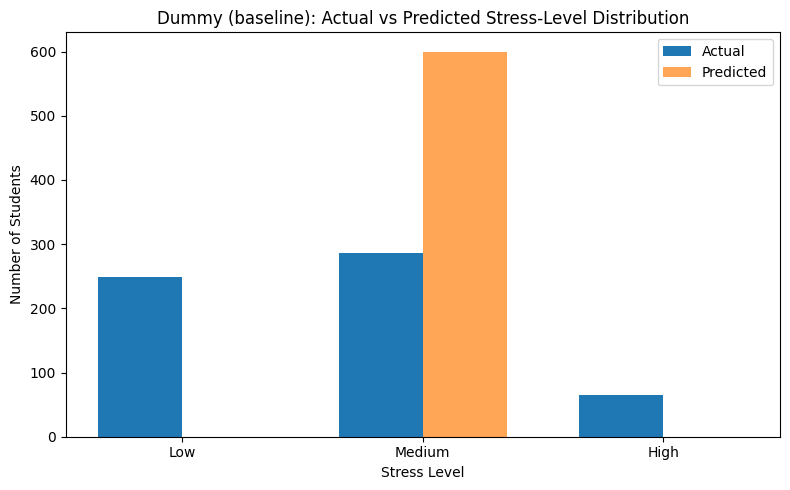

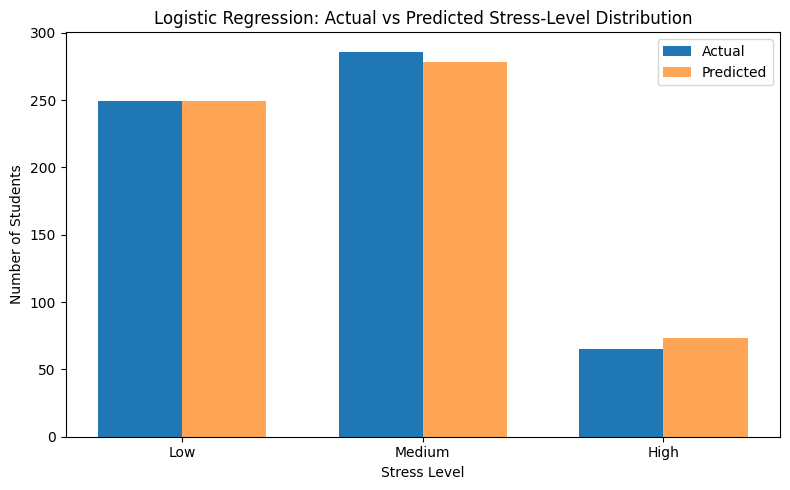

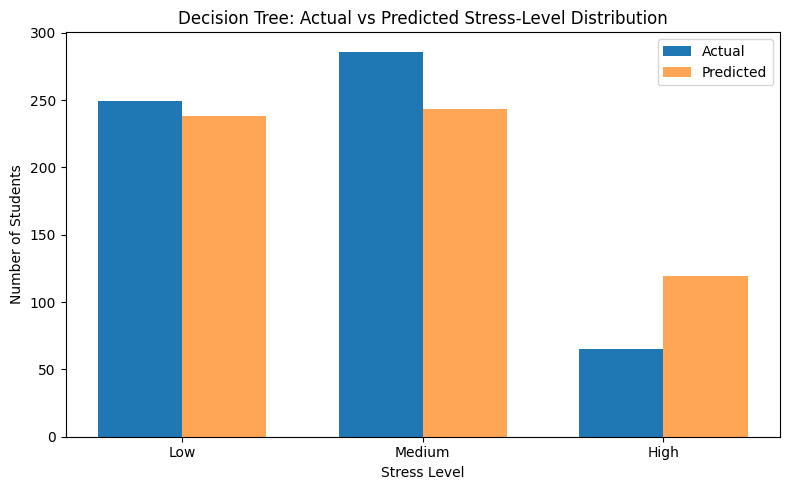

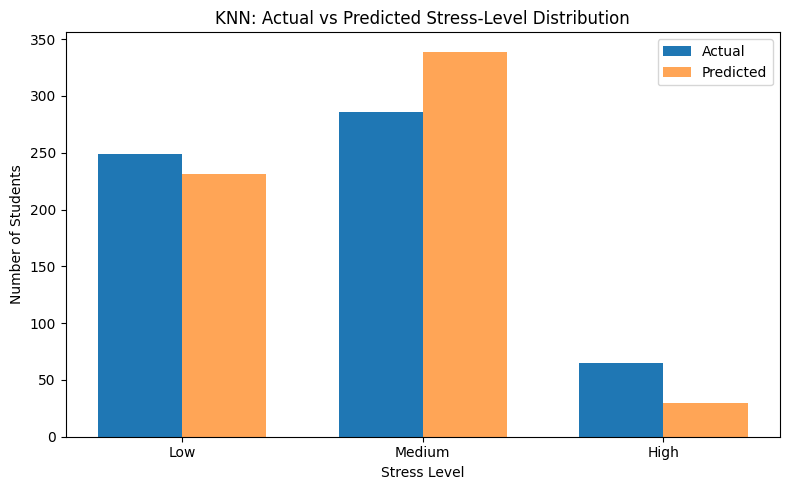

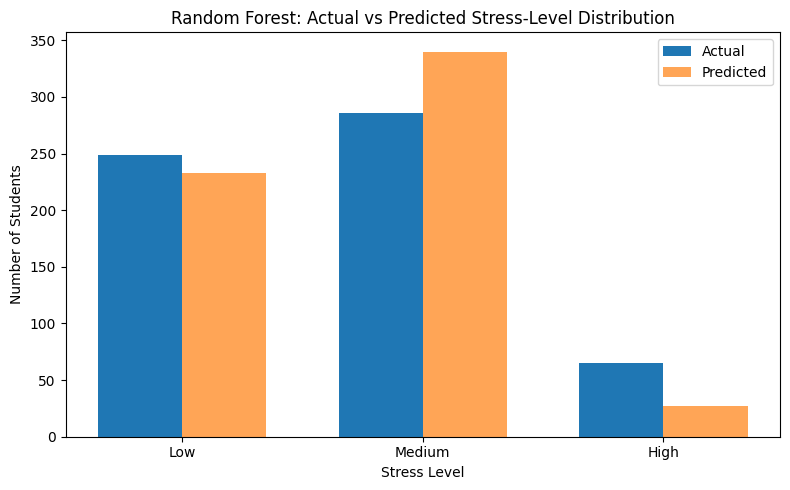

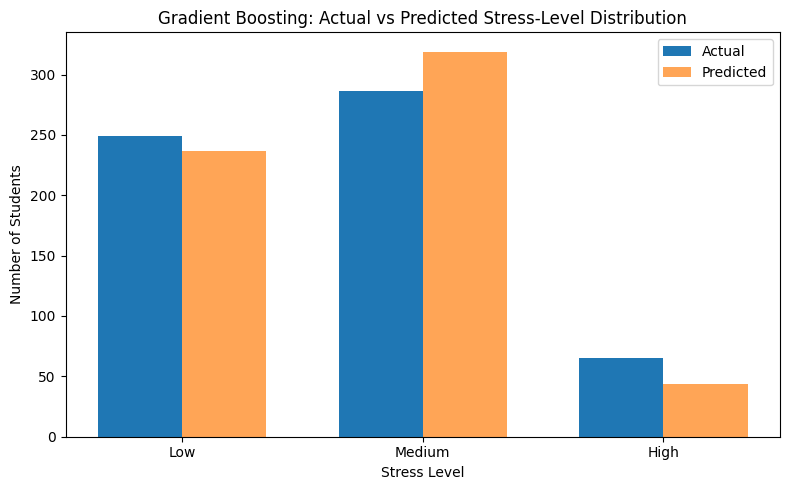

In [ ]:
stress_order = ["Low", "Medium", "High"]

for name, model in pipes_8.items():

    # Predict stress levels on the test set
    pred = model.predict(X_test[FEATURES_8])

    # Count actual and predicted cases in the same category order
    actual_counts = y_test.value_counts().reindex(stress_order, fill_value=0)
    predicted_counts = (pd.Series(pred).value_counts().reindex(stress_order, fill_value=0))

    x = np.arange(len(stress_order))
    width = 0.35

    plt.figure(figsize=(8, 5))

    plt.bar(x - width / 2, actual_counts.values, width, label="Actual")

    plt.bar(x + width / 2, predicted_counts.values, width, label="Predicted", alpha=0.7)

    plt.xticks(x, stress_order)
    plt.xlabel("Stress Level")
    plt.ylabel("Number of Students")
    plt.title(f"{name}: Actual vs Predicted Stress-Level Distribution")
    plt.legend()
    plt.tight_layout()
    plt.show()

### Which of the 8 features does the best model use?

In [ ]:
# Displaying Modelas and Preprocessors
Logistic_8 = pipes_8['Logistic Regression']

display("Pipeline:" , Logistic_8)

display("Preprocessor:" , Logistic_8.named_steps['prep'])
display("Preprocessed Feature Names:" , Logistic_8.named_steps['prep'].get_feature_names_out())

display("Model:" , Logistic_8.named_steps['model'])
display("Model Coeficients:" , Logistic_8.named_steps['model'].coef_)

'Pipeline:'

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('prep', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains s

'Preprocessor:'

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

'Preprocessed Feature Names:'

array(['num__Exam_Frequency', 'num__Assignment_Load', 'num__Sleep_Hours',
       'num__Social_Media_Use', 'num__Screen_Time', 'num__Family_Support',
       'num__Anxiety_Level', 'cat__Physical_Exercise_Yes'], dtype=object)

'Model:'

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :ter

'Model Coeficients:'

array([[ 3.87239706,  3.97363972, -2.41206056,  3.5367984 ,  4.80694246,
        -3.93544517,  3.91066595, -2.82009978],
       [-3.94911048, -3.96375   ,  2.47943283, -3.51520746, -4.82607976,
         3.91063906, -3.9345422 ,  2.87607003],
       [ 0.07671342, -0.00988972, -0.06737227, -0.02159094,  0.01913729,
         0.02480611,  0.02387625, -0.05597025]])

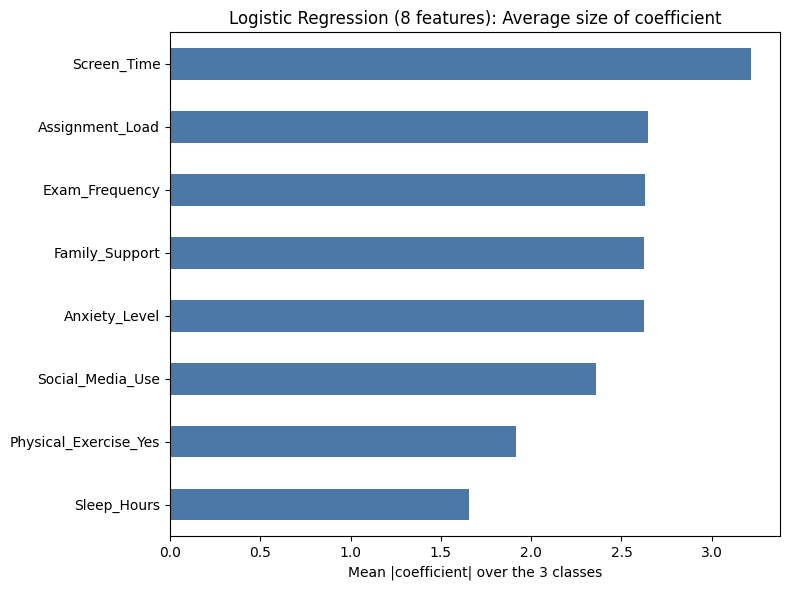

In [ ]:
# Extract the trained Logistic Regression pipeline for the 8-feature subset
lr8 = pipes_8['Logistic Regression']

# Clean up feature names by stripping out the ColumnTransformer prefixes (e.g., 'num__', 'cat__')
names8 = [n.split('__')[1] for n in lr8.named_steps['prep'].get_feature_names_out()]

# Compute the mean absolute coefficient across the 3 classes to gauge overall feature importance
w = pd.Series(np.abs(lr8.named_steps['model'].coef_).mean(axis=0), index=names8).sort_values()

# Plot horizontal bar chart with conditional coloring for prominent features
w.plot.barh(figsize=(8, 6), color=['#4C78A8' if v > 0.5 else '#BBBBBB' for v in w])
plt.title('Logistic Regression (8 features): Average size of coefficient')
plt.xlabel('Mean |coefficient| over the 3 classes')
plt.tight_layout()
plt.show()

### Feature Importance: Logistic Regression Coefficients (8 Features)

This chart ranks the 8 selected features by their overall influence on the multi-class Logistic Regression model.

* **Metric (`Mean |coefficient| over the 3 classes`)**: It calculates the absolute value of **coefficients** ensuring positive and negative impacts are measured equally by magnitude and averages them across all 3 target classes.
* **Interpretation**: Higher values highlight features that strongly drive model decisions (such as `Screen_Time` and `Assignment_Load`), while lower values indicate a comparatively minor impact (such as `Sleep_Hours`).


**Coefficient** here represents the learned weight or multiplier assigned by the Logistic Regression during training. They are numerical values that a mchine learning model adjusts automatically as it learns from data.

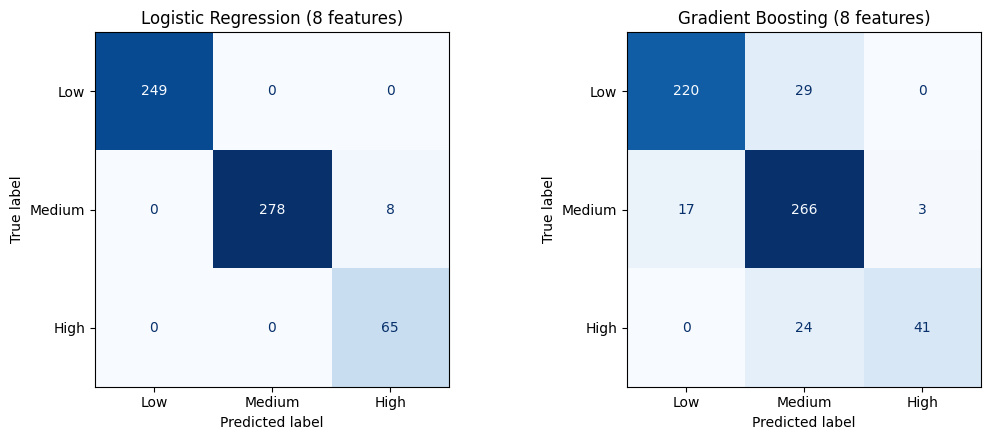

              precision    recall  f1-score   support

         Low       1.00      1.00      1.00       249
      Medium       1.00      0.97      0.99       286
        High       0.89      1.00      0.94        65

    accuracy                           0.99       600
   macro avg       0.96      0.99      0.98       600
weighted avg       0.99      0.99      0.99       600



In [ ]:
# Plot side-by-side confusion matrices for key models using the 8-feature subset
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

for ax, name in zip(axes, ["Logistic Regression", "Gradient Boosting"]):
    y_pred = pipes_8[name].predict(X_test[FEATURES_8])
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=stress_order, cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{name} (8 features)")

plt.tight_layout()
plt.show()

# Generate a detailed classification report for Logistic Regression using the 8-feature model
y_pred_lr = pipes_8["Logistic Regression"].predict(X_test[FEATURES_8])
print(classification_report(y_test, y_pred_lr, labels=stress_order, zero_division=0))

### Model Performance Comparison

The confusion matrices show that **Logistic Regression outperformed Gradient Boosting** in classifying stress levels using the eight selected features. Logistic Regression correctly classified 249 Low, 278 Medium, and 65 High stress cases, achieving **99% accuracy**. It demonstrated excellent performance across all three classes, with only eight Medium cases misclassified as High.

In contrast, Gradient Boosting correctly classified 220 Low, 266 Medium, and 41 High stress cases, with more misclassifications, particularly between Low and Medium stress and between High and Medium stress.

**Overall, Logistic Regression was the better-performing model**, achieving approximately 99% accuracy and a weighted F1-score of 0.99. These results suggest that it effectively distinguishes between the three stress levels in this dataset.

### My Personal Note:
The classification report provides the following evaluation metrics:

- **Precision:** Measures how many predictions for a particular stress level were correct. For example, a precision of 1.00 for Low stress means all cases predicted as Low stress were correct.
- **Recall:** Measures how many actual cases of a stress level the model correctly identified. A recall of 0.97 for Medium stress means the model identified 97% of all actual Medium stress cases.
- **F1-score:** Combines precision and recall into a single measure, balancing both metrics. Values closer to 1.00 indicate better performance.
- **Support:** Indicates the number of actual test samples belonging to each class. The dataset contains 249 Low, 286 Medium, and 65 High stress cases, totalling 600 samples.
- **Accuracy:** Represents the proportion of all test samples correctly classified. It is the overall ratio of correct predictions across all classes (i.e 593/600). The model achieved approximately 99% accuracy.
- **Macro average:** Calculates the unweighted average of the metrics across the three classes, giving each stress level equal importance.
- **Weighted average:** Calculates the average while accounting for the number of samples in each class, giving more weight to classes with more samples. It accounts for class imbalance. If the dataset has  heavily skewed class distributions, the weighted average will closely mirrir the performance of the dominant classs

**Overall interpretation:** Logistic Regression achieved excellent classification performance, with a weighted F1-score of 0.99. Its macro-average F1-score of 0.98 also indicates strong performance across all three stress categories, rather than performance being driven solely by the largest class.

### 4.3 Choosing the final model
Every real model beats the baseline, which only reaches about 0.22 macro-F1 and 48% accuracy by always saying "Medium". Logistic Regression is far ahead of the rest (about 0.97 macro-F1, against about 0.85 to 0.86 for Random Forest and Gradient Boosting, 0.82 for KNN and 0.57 for the shallow Decision Tree). It also catches every High student in the test set. The reason is: The label comes from a *linear* score, so a linear model matches it almost exactly, while trees and neighbours have to approximate a straight boundary with steps. The tree is limited to depth 4 so that it stays readable, which is why it scores lowest.

The ablation table shows that removing the 8 uninformative features costs Logistic Regression nothing (the change is within the cross-validation noise of about 0.01), while the other models improve because they no longer chase noise: Random Forest and Gradient Boosting gain about 0.016, and KNN gains the most (+0.10), because distance-based methods are easily thrown off by irrelevant columns. Decision Tree is unchanged because it was already ignoring them.

**Decision:** Logistic Regression on the 8 features is the final model. It is the most accurate, the simplest, and the one whose explanation is exact, which fits the goal of explainable AI. Gradient Boosting is kept as the "black-box comparison" for the explainability section.

In [ ]:
# From here on, lock in the final 8-feature setup and top-performing models
X = df[FEATURES_8]

cat_cols = [c for c in FEATURES_8 if not pd.api.types.is_numeric_dtype(df[c])]
num_cols = [c for c in FEATURES_8 if c not in cat_cols]

pipes = {
            'Logistic Regression': pipes_8['Logistic Regression'],
            'Gradient Boosting': pipes_8['Gradient Boosting']
        }

print('Final feature count:', len(FEATURES_8))
print('Final features:', FEATURES_8)

Final feature count: 8
Final features: ['Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use', 'Screen_Time', 'Family_Support', 'Anxiety_Level', 'Physical_Exercise']


## 5. Explainable AI
Using complementary views, from global to individual:

| Method | Question it answers | Scope |
|----|----|----|
| Model coefficients | In which direction and how strongly does each feature push a class? | Global, built into the model |
| Permutation importance | How much worse does the model get if a feature is scrambled? | Global, any model |
| SHAP values | How much did each feature contribute to this prediction? | Global and individual |
| Per-student explanation | Why did the model give *this* student *this* label? | Individual (shown in Streamlit) |

### 5.1 Logistic Regression coefficients (inherent interpretability)
Features were standardised, so each coefficient is the change in log-odds for a 1-standard-deviation increase. Positive means the feature pushes towards that class.

#### My Personal Note
**Model coefficients** are the classic, gold standard method for explaining inherently interpretable (white-box) models, such as linear regression, logistic regression.
Unlike post-hoc technoques (like LIME or SHAP) that guess how a black box-model works, coefficients tell you **exactly how the model claculates its output** because they are actual math driving the system

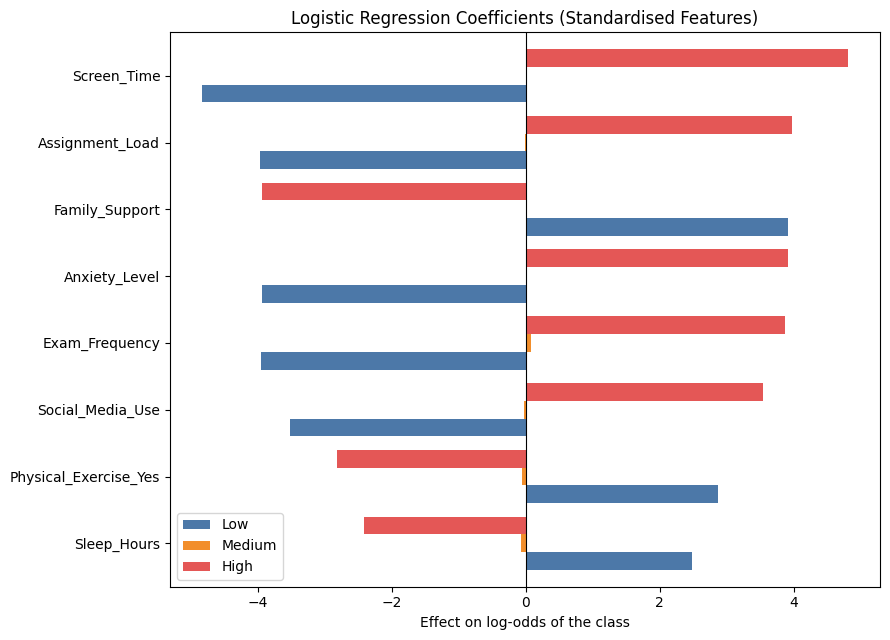

,Low,Medium,High
Screen_Time,-4.83,0.02,4.81
Assignment_Load,-3.96,-0.01,3.97
Anxiety_Level,-3.93,0.02,3.91
Exam_Frequency,-3.95,0.08,3.87
Social_Media_Use,-3.52,-0.02,3.54
Sleep_Hours,2.48,-0.07,-2.41
Physical_Exercise_Yes,2.88,-0.06,-2.82
Family_Support,3.91,0.02,-3.94


In [ ]:
# Extract the final Logistic Regression pipeline and its feature names
best = pipes['Logistic Regression']
feat_names = [n.split('__')[1] for n in best.named_steps['prep'].get_feature_names_out()]

# Construct a coefficient DataFrame mapped to the class labels and feature names
coef = pd.DataFrame(best.named_steps['model'].coef_, index=best.named_steps['model'].classes_, columns=feat_names).T

# Reorder columns to match the defined stress progression order
coef = coef[stress_order]

# Sort features by the magnitude of their coefficient for the 'High' stress class
coef['abs_high'] = coef['High'].abs()
coef = coef.sort_values('abs_high', ascending=True).drop(columns='abs_high')

# Plot side-by-side horizontal bar chart comparing 'Low' and 'High' stress impacts
coef[['Low', 'Medium', 'High']].plot.barh(figsize=(9, 6.5), width=0.8, color=['#4C78A8', '#F28E2B', '#E45756'])
plt.axvline(0, color='k', lw=0.8)
plt.title('Logistic Regression Coefficients (Standardised Features)')
plt.xlabel('Effect on log-odds of the class')
plt.tight_layout()
plt.show()

# Display the sorted, rounded coefficient table for precise numerical review
coef.round(2).sort_values('High', ascending=False)

**Interpretation:** For High stress, the largest positive pushes come from `Screen_Time`, `Exam_Frequency`, `Assignment_Load`, `Social_Media_Use` and `Anxiety_Level`. The largest negative pushes come from `Family_Support`, `Sleep_Hours` and `Physical_Exercise_Yes`. The Low-stress bars are the mirror image. All eight selected features have clearly non-zero coefficients, which is why dropping the other eight (section 4.2) lost nothing.

### 5.2 Permutation importance (model-agnostic)
Permutation Feature Importance analysis identifies which features were important to the model overall.

Each feature in the **test set** is shuffled in turn and measure how much macro-F1 drops. A big drop means the model relies on that feature. It works for any model, so I compute it for both `Logistic Regression` & `Gradient Boosting`.

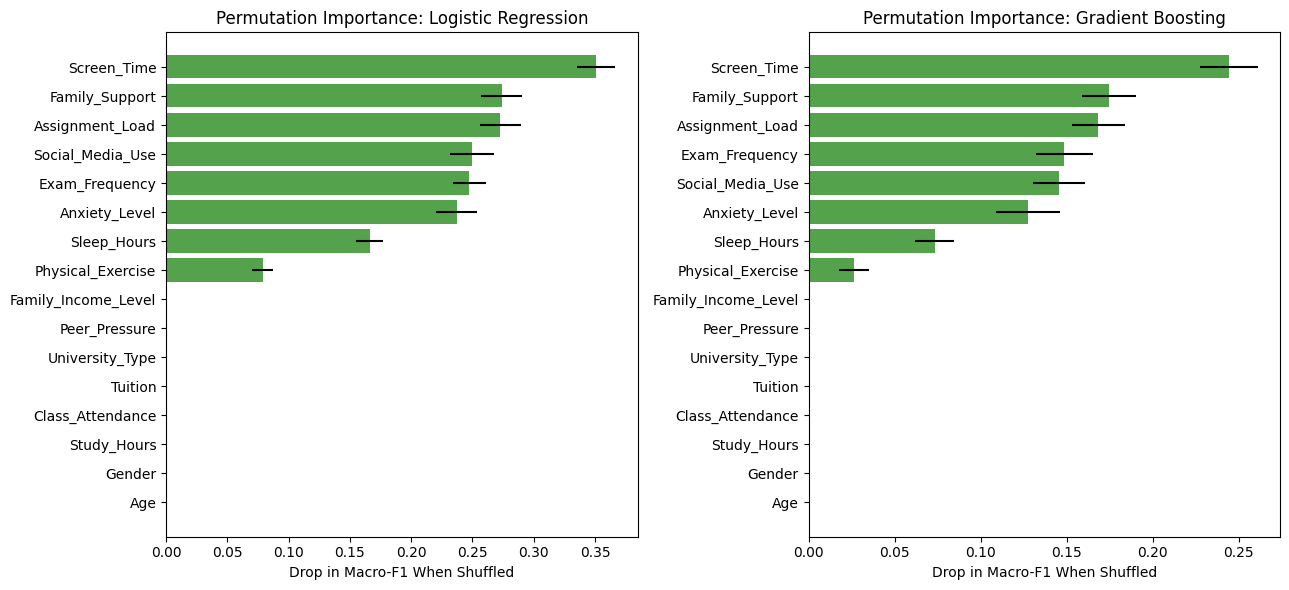

,mean,std
Screen_Time,0.351,0.016
Family_Support,0.274,0.017
Assignment_Load,0.273,0.016
Social_Media_Use,0.249,0.018
Exam_Frequency,0.248,0.014
Anxiety_Level,0.237,0.017
Sleep_Hours,0.166,0.011
Physical_Exercise,0.079,0.009
Family_Income_Level,0.000,0.000
Peer_Pressure,0.000,0.000


In [ ]:
from sklearn.inspection import permutation_importance

# Shuffle one feature at a time on the test set and see how much macro-F1 drops
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
perm_tables = {}

model_names = ['Logistic Regression', 'Gradient Boosting']
for i in range(2):
    name = model_names[i]
    result = permutation_importance(pipes[name], X_test, y_test, scoring='f1_macro',
                                    n_repeats=20, random_state=42, n_jobs=-1)

    table = pd.DataFrame({'mean': result.importances_mean, 'std': result.importances_std}, index=X_test.columns)
    table = table.sort_values('mean')
    perm_tables[name] = table

    axes[i].barh(table.index, table['mean'], xerr=table['std'], color='#54A24B')
    axes[i].set_title('Permutation Importance: ' + name)
    axes[i].set_xlabel('Drop in Macro-F1 When Shuffled')

plt.tight_layout()
plt.show()

# top features for Logistic Regression
perm_tables['Logistic Regression'].sort_values('mean', ascending=False).round(3).head(10)

In [ ]:
# Compare mean permutation importance across models

comparison = pd.DataFrame({
    'Logistic Regression':
        perm_tables['Logistic Regression']['mean'],


    'Gradient Boosting':
        perm_tables['Gradient Boosting']['mean']
})

comparison = comparison.sort_values(
    'Logistic Regression',
    ascending=False
)

display(comparison.round(3))

,Logistic Regression,Gradient Boosting
Screen_Time,0.351,0.244
Family_Support,0.274,0.174
Assignment_Load,0.273,0.168
Social_Media_Use,0.249,0.145
Exam_Frequency,0.248,0.149
Anxiety_Level,0.237,0.127
Sleep_Hours,0.166,0.073
Physical_Exercise,0.079,0.026
Gender,0.000,0.000
Family_Income_Level,0.000,0.000


**Interpretation:** Both models rank the features in almost the same order (the Gradient Boosting bars are shorter because it is the weaker model here). Shuffling `Screen_Time` hurts the model the most, followed by `Family_Support`, `Assignment_Load`, `Social_Media_Use`, `Exam_Frequency`, `Anxiety_Level`, `Sleep_Hours` and `Physical_Exercise`. Every one of the eight matters, so none of them can be removed without a visible loss. Having two different model types agree on the ranking makes the finding more trustworthy.

### 5.3 SHAP (SHapley Additive exPlanations) values
SHAP goes further by examining how much each feature contributes to the model's output for individual observations and across different target classes.

SHAP splits each prediction into a contribution per feature (in log-odds). Averaging the absolute values gives global importance. The plot below shows the contribution to each of the three classes.

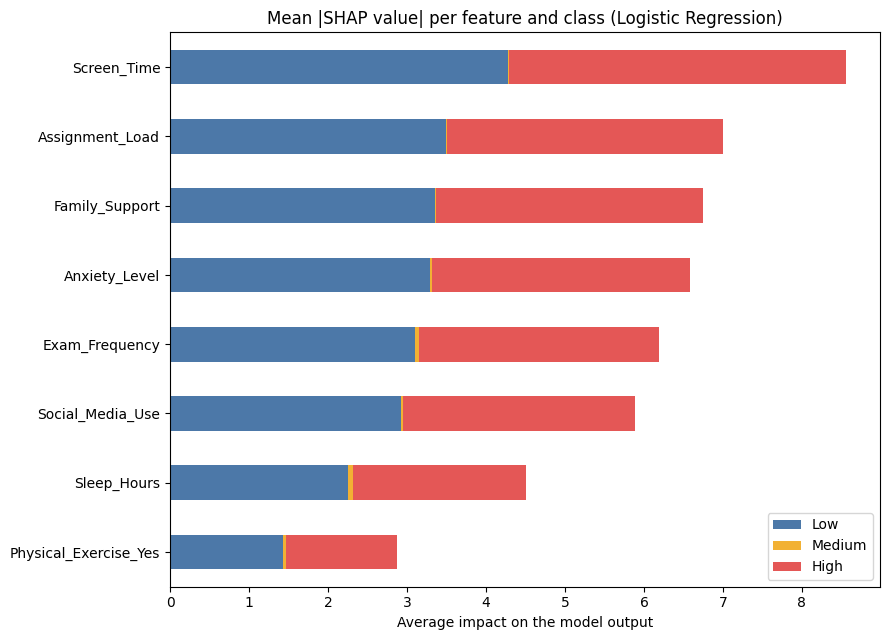

In [ ]:
import shap

# Retrieve the preprocessed (scaled) component from the trained machine leearning pipeline
prep = best.named_steps['prep'] # best is the complete trained pipeline, named_steps accesses the pipeline components.

# Extracting the trained classification model
clf = best.named_steps['model'] # best is the complete trained pipeline, named_steps accesses the pipeline components,
                                # clf stores the extracted classifier.

# Transform training and test sets using the fitted preprocessing pipeline
Xtr_t = prep.transform(X_train)
Xte_t = prep.transform(X_test)

# Initialize SHAP LinearExplainer using an Independent masker for the background distribution
explainer = shap.LinearExplainer(clf, shap.maskers.Independent(Xtr_t, max_samples=len(Xtr_t)))
sv = explainer.shap_values(Xte_t)

# Ensure shape is consistent for multi-class outputs -> (rows, features, classes/stress levels)
sv = np.stack(sv, axis=-1) if isinstance(sv, list) else sv
classes = list(clf.classes_)

# Compute mean absolute SHAP values per feature and class, aligned with stress order
mean_abs = pd.DataFrame(np.abs(sv).mean(axis=0), index=feat_names, columns=classes)[stress_order]
mean_abs = mean_abs.loc[mean_abs.sum(axis=1).sort_values().index]

# Plot stacked horizontal bar chart showing multi-class impact breakdown
mean_abs.plot.barh(stacked=True, figsize=(9, 6.5), color=['#4C78A8', '#F2B134', '#E45756'])
plt.title('Mean |SHAP value| per feature and class (Logistic Regression)')
plt.xlabel('Average impact on the model output')
plt.tight_layout()
plt.show()

1. **`Screen_Time` is the most influential feature** (about 8.5 in total, roughly 4.3 for Low and 4.3 for High), followed by `Assignment_Load` (about 7.0), `Family_Support` (6.7), `Anxiety_Level` (6.6), `Exam_Frequency` (6.2), `Social_Media_Use` (5.9), `Sleep_Hours` (4.5) and `Physical_Exercise_Yes` (2.9).
2. **The Low and High segments are almost equal, and the Medium segment is tiny** for every feature. That is the same pattern as in the coefficient chart: Low and High mirror each other and the Medium class barely reacts to any single feature.
3. **Compared with the coefficient chart,** the order is more sensible. In the coefficient chart `Physical_Exercise_Yes` looked stronger than `Sleep_Hours`; here `Sleep_Hours` is ahead. SHAP multiplies each coefficient by how much the feature actually varies between students, so it puts the Yes/No column and the numeric columns on a fair footing.

**The scale.** SHAP values here are in the model's raw score (log-odds) units, not probabilities. They are good for comparing features with each other and for seeing direction, but a value of 4 does not mean "4% more likely".

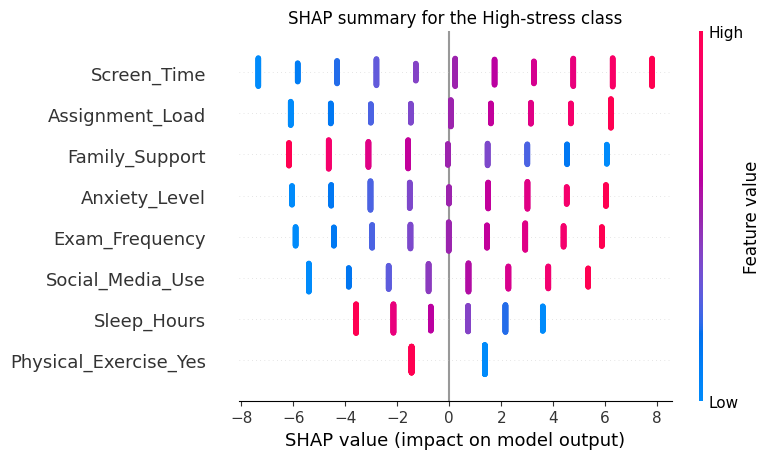

In [ ]:
# Direction of the effect on High stress: each dot represents a student
hi = classes.index('High')

# Generate SHAP summary plot (beeswarm) for the High-stress class
shap.summary_plot(sv[:, :, hi], Xte_t, feature_names=feat_names, show=False, max_display=10)
plt.title('SHAP summary for the High-stress class')
plt.tight_layout()
plt.show()

The visualization reveals the following patterns:

1. Screen Time: Screen time is one of the most influential features in the model. Students with higher screen-time values (red marks) generally have positive SHAP values, indicating an increased likelihood of being classified as highly stressed. Conversely, lower screen-time values (blue marks) tend to push predictions towards the lower-stress category. This suggests a positive relationship between excessive screen time and student stress.

2. Assignment Load: Higher assignment loads generally contribute positively to the prediction of high stress. This indicates that students with heavier academic workloads are more likely to be classified as highly stressed, while lower assignment loads tend to reduce the model's prediction of high stress.

3. Family Support: Family support demonstrates an opposite relationship. Higher levels of family support (red marks) generally produce negative SHAP values, suggesting that strong family support reduces the likelihood of a student being classified as highly stressed. Lower family support (blue marks), however, tends to increase the prediction of high stress. This highlights the potential importance of family support in students' emotional well-being.

4. Anxiety Level: Higher anxiety levels contribute positively to the prediction of high stress, as indicated by the red marks on the positive side of the plot. Lower anxiety levels generally contribute negatively. This suggests that anxiety is an important indicator associated with students experiencing high stress.

5. Exam Frequency: Students with higher examination frequency generally have positive SHAP values, indicating that frequent examinations may contribute to increased stress predictions. Lower examination frequency tends to have the opposite effect.

6. Social Media Use: Higher social media usage generally pushes the model towards predicting high stress, while lower usage tends to reduce this prediction. This suggests that excessive social media engagement may be associated with increased stress among students.

7. Sleep Hours: Sleep hours demonstrate an inverse relationship with stress predictions. Higher sleep-hour values generally produce negative SHAP values, suggesting that adequate sleep reduces the likelihood of being classified as highly stressed. Conversely, lower sleep-hour values tend to increase the model's prediction of high stress.

8. Physical Exercise: Physical exercise appears to have a protective influence. The plot shows the higher feature value (red mark) on the negative SHAP side and the lower feature value (blue mark) on the positive side. Assuming the binary encoding represents Yes = 1 and No = 0, this suggests that students who engage in physical exercise are less likely to be classified as highly stressed than those who do not.

Student Features: {'Age': 22, 'Gender': 'Female', 'Study_Hours': 3, 'Class_Attendance': 79, 'Tuition': 'No', 'Exam_Frequency': 9, 'Assignment_Load': 4, 'Sleep_Hours': 5, 'Physical_Exercise': 'No', 'Social_Media_Use': 5, 'Screen_Time': 11, 'Family_Income_Level': 'High', 'Peer_Pressure': 4, 'Family_Support': 2, 'Anxiety_Level': 9, 'University_Type': 'Public University'}
Prediction: High
Class Probabilities: {'High': 1.0, 'Low': 0.0, 'Medium': 0.0}


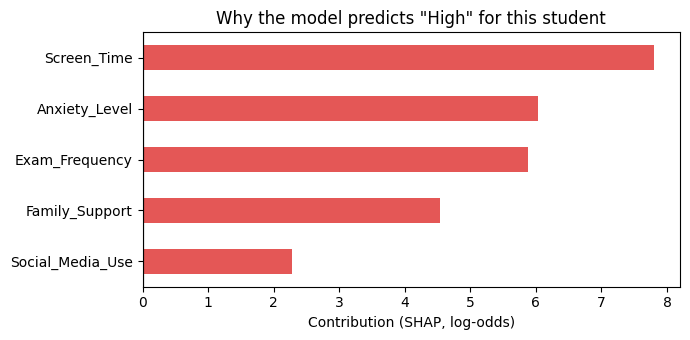

In [ ]:
def explain_student(student: dict, top_n: int = 5):
    """Explains an individual student's stress prediction using local SHAP values
    and returns the predicted class, class probabilities, and top contributing features.
    """
    row = pd.DataFrame([student])[X.columns]
    proba = best.predict_proba(row)[0]
    pred = clf.classes_[proba.argmax()]

    # Compute local SHAP values for the single student instance
    contrib = explainer.shap_values(prep.transform(row))
    contrib = np.stack(contrib, axis=-1) if isinstance(contrib, list) else contrib

    # Extract feature contributions for the predicted class
    c = pd.Series(contrib[0, :, list(clf.classes_).index(pred)], index=feat_names)
    top = c.reindex(c.abs().sort_values(ascending=False).index).head(top_n)

    return pred, {k: round(float(v), 3) for k, v in zip(clf.classes_, proba)}, top


# Identify and select the highest-risk student in the test set
idx = best.predict_proba(X_test)[:, list(clf.classes_).index('High')].argmax()
student = X_test.iloc[idx].to_dict()

pred, probs, top = explain_student(student)

print('Student Features:', student)
print('Prediction:', pred)
print('Class Probabilities:', probs)

# Plot local feature contributions for this specific student
top.sort_values().plot.barh(color=['#E45756' if v > 0 else '#4C78A8' for v in top.sort_values()], figsize=(7, 3.5))
plt.axvline(0, color='k', lw=0.8)
plt.title(f'Why the model predicts "{pred}" for this student')
plt.xlabel('Contribution (SHAP, log-odds)')
plt.tight_layout()
plt.show()

**Interpretation:** this chart answers "why this label?" for a single student. Red bars push towards the predicted class and blue bars push against it. For the student shown, the biggest pushes towards High are a screen time of 11 hours, an anxiety rating of 9, an exam frequency of 9 and a family-support rating of only 2. A counsellor can read it directly. The predicted probability is 1.0 because the labels follow an exact rule, so on real data you should expect less extreme probabilities. In Streamlit, show the probabilities, the top 5 contributors in plain words, and a clear note that this is a screening aid and not a diagnosis.

# 6. Hyperparameter tuning
So far every model used its default settings. Here the **Logistic Regression** tuned with 5-fold cross-validation on the **training data only**, scored with macro-F1. The test set is touched only afterwards, so it stays an honest exam.

In [ ]:
good_rows

,C,class_weight,cv_macro_F1,cv_std
6,10.0,None,1.0,0.0
8,100.0,None,1.0,0.0


In [ ]:
import itertools
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix

cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ----- Logistic Regression: try 5 values of C, with and without class weights -----
lr_search = GridSearchCV(
                            estimator= pipes_8['Logistic Regression'],
                            param_grid={'model__C': [0.01, 0.1, 1, 10, 100],
                                        'model__class_weight': [None, 'balanced']},
                            cv=cv5,
                            scoring='f1_macro',
                            n_jobs=-1,
                                                 )
lr_search.fit(X_train, y_train)

lr_results = pd.DataFrame(lr_search.cv_results_)[['param_model__C', 'param_model__class_weight', 'mean_test_score', 'std_test_score']]
lr_results.columns = ['C', 'class_weight', 'cv_macro_F1', 'cv_std']
print('Logistic Regression: cross-validated macro-F1 for every setting (training data only)')
display(lr_results.sort_values('cv_macro_F1', ascending=False).round(4).reset_index(drop=True))

# Pick the simplest setting that is about as good as the best:
# keep every row within 0.001 of the best score, then take the smallest C (and no class weights if possible).
best_score = lr_results['cv_macro_F1'].max()
good_rows = lr_results[lr_results['cv_macro_F1'] >= best_score - 0.001]

rows_without_weights = good_rows[good_rows['class_weight'].isna()]
if len(rows_without_weights) > 0:
    good_rows = rows_without_weights
    chosen_weight = None
else:
    chosen_weight = 'balanced'

chosen_C = float(good_rows['C'].min())
print('\nChosen Logistic Regression: C =', chosen_C, ', class_weight =', chosen_weight)

Logistic Regression: cross-validated macro-F1 for every setting (training data only)


,C,class_weight,cv_macro_F1,cv_std
0,100.00,balanced,1.0000,0.0000
1,100.00,None,1.0000,0.0000
2,10.00,None,1.0000,0.0000
3,10.00,balanced,0.9969,0.0038
4,1.00,None,0.9936,0.0033
5,1.00,balanced,0.9664,0.0108
6,0.10,None,0.9492,0.0127
7,0.10,balanced,0.9472,0.0162
8,0.01,balanced,0.8867,0.0174
9,0.01,None,0.7057,0.0258



Chosen Logistic Regression: C = 10.0 , class_weight = None


**Interpretation:**

**The Logistic Regression's** The cross-validated macro-F1 climbs as `C` grows (less regularisation): 0.71 at C = 0.01, 0.99 at C = 1, and a perfect 1.000 at C = 10 and C = 100. Heavy regularisation was *hurting* the model, because it shrank the coefficients below the size the true rule needs. I used a simplicity rule: among settings within 0.001 of the best score, take the smallest `C`. That gives **C = 10 with no class weights**. Class weights made no difference to the best score, which fits the fact that the three classes are not extremely imbalanced.

# 7. Saving the final model for Streamlit

In [ ]:
# 1. Load the data and choose the columns
df = pd.read_csv('university_student_stress_dataset.csv')

features = ['Exam_Frequency', 'Assignment_Load', 'Sleep_Hours', 'Social_Media_Use',
            'Screen_Time', 'Family_Support', 'Anxiety_Level', 'Physical_Exercise']
number_columns = [c for c in features if c != 'Physical_Exercise']

X = df[features]                  # Stress_Score is NOT used, it would leak the answer
y = df['Stress_Level']

# 2. Split into training and test data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 3. Build and train the model: scale numbers, encode Yes/No, then Logistic Regression (C=10 came from tuning)
preprocessing = ColumnTransformer([
                                        ('num', StandardScaler(), number_columns),
                                        ('cat', OneHotEncoder(drop='if_binary', handle_unknown='ignore'), ['Physical_Exercise']),
                                    ])
model = Pipeline([('prep', preprocessing), ('model', LogisticRegression(C=10, max_iter=5000))])
model.fit(X_train, y_train)

# 4. Settings the app needs next to the model
ranges = {}
averages = {}
for column in number_columns:
    ranges[column] = [int(X[column].min()), int(X[column].max())]     # slider limits
    averages[column] = float(X_train[column].mean())                  # the "average student"

scaled_train = model.named_steps['prep'].transform(X_train)
scaled_names = []
for name in model.named_steps['prep'].get_feature_names_out():
    scaled_names.append(name.split('__')[1])

# 5. Save everything in ONE file
saved = {
            'model': model,
            'features': features,
            'ranges': ranges,
            'averages': averages,
            'scaled_averages': scaled_train.mean(axis=0),
            'scaled_names': scaled_names,
        }

joblib.dump(saved, 'stress_model.joblib')
print('Saved stress_model.joblib')


Saved stress_model.joblib


# 8. Limitations and Conclusion

## 8.1 Limitations

1. **The labels are a formula.** `Stress_Level` is a threshold of `Stress_Score`, which is an exact sum of eight columns. The near perfect scores show that the pipeline can recover a rule.
2. **The data target classes are imbalanced.**
3. **Single dataset, single split.** The models were never tested on a second dataset.
4. **Not a diagnosis.** It can not replace a counsellor or clinician.

## 8.2 Conclusion

A full pipeline was built and checked: data validation, EDA, chi-square and Kruskal-Wallis tests (with Cramér's V and epsilon-squared), a VIF check, feature selection down to 8 informative features, a comparison of six models, hyperparameter tuning, three explainability methods (coefficients, permutation importance, SHAP), what-if explanations, calibration and a fairness check. Logistic Regression was the best model and the most explainable one. The key finding is as much about **method** as about accuracy: a leakage check and a regression on the score revealed that the dataset follows a rule, and that is why a simple, transparent model wins.
